# Analyse climatique de l’Algérie — ERA5-Land (2015–2025)

## Partie 1 — Data Analysis and Preprocessing
## Partie 2 — Supervised Machine Learning
## Partie 3 — Unsupervised Machine Learning (Clustering)

Notebook complet aligné sur le sujet du projet DATA MINING USTHB 2026–2027.

**Avant de commencer :** adaptez uniquement `NC_PATH` et `GEOJSON_PATH` dans la cellule de configuration. Exécutez ensuite toutes les cellules dans l’ordre.

Le notebook utilise les variables ERA5 demandées dans le sujet. La réduction spatiale ×4 est réalisée par agrégation de blocs 4×4 après sélection géographique. Les données actuelles peuvent couvrir janvier 2015 à décembre 2025 selon le fichier NetCDF fourni.


## 0. Installation des bibliothèques

In [7]:
%pip install -q numpy pandas xarray netCDF4 matplotlib seaborn scikit-learn shapely scipy

Note: you may need to restart the kernel to use updated packages.


## 0.1 Imports et configuration

In [11]:
from pathlib import Path
import json, warnings, time
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from shapely.geometry import shape, Point
from shapely.prepared import prep
from shapely.ops import unary_union

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, matthews_corrcoef,
    silhouette_score, davies_bouldin_score, calinski_harabasz_score
)
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

from pathlib import Path

BASE_DIR = Path(r"C:\Users\DELL\Desktop\M2\data mining\data")

NC_PATH = BASE_DIR / "97a482e22d0cb0b4273cb0928c26ced.nc"
GEOJSON_PATH = BASE_DIR / "dz.json"

print("NetCDF :", NC_PATH.exists(), NC_PATH)
print("GeoJSON :", GEOJSON_PATH.exists(), GEOJSON_PATH)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

TARGET_VAR = "t2m"
TEST_SIZE = 0.20
N_CLASSES = 3
RANDOM_STATE = 42
SPATIAL_FACTOR = 4
MAX_SUPERVISED_TRAIN = 40000  # limite pratique pour un PC avec 8 Go RAM
MAX_CLUSTER_POINTS = 2500     # AGNES/DBSCAN sont coûteux sur de très grands jeux

# Variables imposées par l'énoncé (hors t2m qui est la cible)
SUPERVISED_FEATURES = [
    "d2m", "slhf", "ssr", "str", "sshf", "ro", "e",
    "u10", "v10", "sp", "tp"
]
REQUIRED_VARS = ["t2m"] + SUPERVISED_FEATURES
WIND_COMPONENTS = ["u10", "v10"]
VAR_LABELS = {
    "t2m": "2 m temperature", "d2m": "2 m dewpoint temperature",
    "slhf": "Surface latent heat flux", "ssr": "Surface net solar radiation",
    "str": "Surface net thermal radiation", "sshf": "Surface sensible heat flux",
    "ro": "Runoff", "e": "Total evaporation", "u10": "10 m u-component of wind",
    "v10": "10 m v-component of wind", "sp": "Surface pressure",
    "tp": "Total precipitation", "wind_speed": "10 m wind speed"
}
CLASS_NAMES = ["Froide", "Modérée", "Chaude"]
print("Dossier de travail :", BASE_DIR.resolve())
print("NetCDF :", NC_PATH)
print("GeoJSON :", GEOJSON_PATH)

NetCDF : True C:\Users\DELL\Desktop\M2\data mining\data\97a482e22d0cb0b4273cb0928c26ced.nc
GeoJSON : True C:\Users\DELL\Desktop\M2\data mining\data\dz.json
Dossier de travail : C:\Users\DELL\Desktop\M2\data mining\data
NetCDF : C:\Users\DELL\Desktop\M2\data mining\data\97a482e22d0cb0b4273cb0928c26ced.nc
GeoJSON : C:\Users\DELL\Desktop\M2\data mining\data\dz.json


## 1.1 Chargement des données et sélection géographique de l’Algérie

In [14]:
def load_algeria_geometry(path):
    with open(path, "r", encoding="utf-8") as file:
        geojson = json.load(file)
    kind = geojson.get("type")
    if kind == "FeatureCollection":
        geoms = [shape(f["geometry"]) for f in geojson.get("features", []) if f.get("geometry")]
    elif kind == "Feature":
        geoms = [shape(geojson["geometry"])]
    else:
        geoms = [shape(geojson)]
    geoms = [g for g in geoms if g is not None and not g.is_empty]
    if not geoms:
        raise ValueError("Aucune géométrie valide dans le GeoJSON.")
    return unary_union(geoms)


def find_coordinate_name(ds, candidates):
    for name in candidates:
        if name in ds.coords:
            return name
    raise KeyError(f"Coordonnée introuvable parmi {candidates}. Coordonnées : {list(ds.coords)}")

if not NC_PATH.exists():
    raise FileNotFoundError(f"NetCDF introuvable : {NC_PATH}. Modifiez NC_PATH.")
if not GEOJSON_PATH.exists():
    raise FileNotFoundError(f"GeoJSON introuvable : {GEOJSON_PATH}. Modifiez GEOJSON_PATH.")

algeria_geometry = load_algeria_geometry(GEOJSON_PATH)
ds = xr.open_dataset(NC_PATH)
lat_name = find_coordinate_name(ds, ["latitude", "lat"])
lon_name = find_coordinate_name(ds, ["longitude", "lon"])
time_name = find_coordinate_name(ds, ["valid_time", "time"])

# Résoudre les dimensions auxiliaires éventuelles (number/expver) si elles sont singleton.
for dim in ["number", "expver"]:
    if dim in ds.dims and ds.sizes[dim] == 1:
        ds = ds.isel({dim: 0}, drop=True)

missing_vars = [v for v in REQUIRED_VARS if v not in ds.data_vars]
if missing_vars:
    raise KeyError(f"Variables ERA5 manquantes : {missing_vars}. Variables disponibles : {list(ds.data_vars)}")

# Sous-ensemble géographique rectangulaire avant masque précis
minx, miny, maxx, maxy = algeria_geometry.bounds
lat_values = ds[lat_name].values
lat_slice = slice(miny, maxy) if lat_values[0] < lat_values[-1] else slice(maxy, miny)
ds = ds.sel({lat_name: lat_slice, lon_name: slice(minx, maxx)}).sortby(time_name)

# Masque des centres de grille appartenant à l'Algérie
prepared = prep(algeria_geometry)
lon_grid, lat_grid = np.meshgrid(ds[lon_name].values, ds[lat_name].values)
inside_array = np.array([
    prepared.covers(Point(float(x), float(y)))
    for x, y in zip(lon_grid.ravel(), lat_grid.ravel())
]).reshape(lon_grid.shape)
inside_cells = xr.DataArray(
    inside_array,
    coords={lat_name: ds[lat_name], lon_name: ds[lon_name]},
    dims=[lat_name, lon_name], name="inside_algeria"
)
ds = ds.where(inside_cells)

# Réduction spatiale obligatoire : agrégation des cellules voisines en blocs 4×4.
# Les NaN hors Algérie ne contribuent pas à la moyenne.
coarse_ds = ds[REQUIRED_VARS].coarsen(
    {lat_name: SPATIAL_FACTOR, lon_name: SPATIAL_FACTOR}, boundary="trim"
).mean()

# Un bloc est conservé si au moins un centre d'origine appartenait à l'Algérie.
inside_cells_coarse = inside_cells.coarsen(
    {lat_name: SPATIAL_FACTOR, lon_name: SPATIAL_FACTOR}, boundary="trim"
).max().astype(bool)
coarse_ds = coarse_ds.where(inside_cells_coarse)

# Vitesse du vent pour l'EDA uniquement ; u10 et v10 restent séparés dans le modèle.
coarse_ds["wind_speed"] = np.hypot(coarse_ds["u10"], coarse_ds["v10"])
coarse_ds["wind_speed"].attrs["units"] = "m/s"

print("Coordonnées :", time_name, lat_name, lon_name)
print("Période :", pd.to_datetime(coarse_ds[time_name].values).min(), "→", pd.to_datetime(coarse_ds[time_name].values).max())
print("Dimensions après réduction ×4 :", dict(coarse_ds.sizes))
print("Nombre de blocs spatiaux dans le masque :", int(inside_cells_coarse.sum().item()))
display(coarse_ds)

Coordonnées : valid_time latitude longitude
Période : 2015-01-01 00:00:00 → 2025-12-01 00:00:00
Dimensions après réduction ×4 : {'valid_time': 132, 'latitude': 45, 'longitude': 51}
Nombre de blocs spatiaux dans le masque : 1410


<xarray.Dataset> Size: 16MB
Dimensions:     (valid_time: 132, latitude: 45, longitude: 51)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 1kB 2015-01-01 ... 2025-12-01
    expver      (valid_time) <U4 2kB ...
  * latitude    (latitude) float64 360B 36.85 36.45 36.05 ... 20.05 19.65 19.25
  * longitude   (longitude) float64 408B -8.45 -8.05 -7.65 ... 10.75 11.15 11.55
    number      int64 8B ...
Data variables: (12/13)
    t2m         (valid_time, latitude, longitude) float32 1MB nan nan ... nan
    d2m         (valid_time, latitude, longitude) float32 1MB nan nan ... nan
    slhf        (valid_time, latitude, longitude) float32 1MB nan nan ... nan
    ssr         (valid_time, latitude, longitude) float32 1MB nan nan ... nan
    str         (valid_time, latitude, longitude) float32 1MB nan nan ... nan
    sshf        (valid_time, latitude, longitude) float32 1MB nan nan ... nan
    ...          ...
    e           (valid_time, latitude, longitude) float32 1MB nan nan ... nan
    u10         (valid_time, latitude, longitude) float32 1MB nan nan ... nan
    v10         (valid_time, latitude, longitude) float32 1MB nan nan ... nan
    sp          (valid_time, latitude, longitude) float32 1MB nan nan ... nan
    tp          (valid_time, latitude, longitude) float32 1MB nan nan ... nan
    wind_speed  (valid_time, latitude, longitude) float32 1MB nan nan ... nan
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-01T12:27 GRIB to CDM+CF via cfgrib-0.9.1...

## 1.2 Dataset Overview et dictionnaire des variables

In [15]:
overview_rows = []
for variable in REQUIRED_VARS + ["wind_speed"]:
    da = coarse_ds[variable]
    valid_area = inside_cells_coarse.broadcast_like(da)
    total_cells = int(valid_area.sum().item())
    missing_count = int((da.isnull() & valid_area).sum().item())
    values = da.where(inside_cells_coarse).values
    valid_values = values[np.isfinite(values)]
    overview_rows.append({
        "Variable": variable,
        "Description": VAR_LABELS.get(variable, variable),
        "Units": da.attrs.get("units", "unknown"),
        "Valid observations": int(valid_values.size),
        "Missing observations": missing_count,
        "Missing (%)": 100 * missing_count / total_cells if total_cells else np.nan,
        "Minimum": float(np.nanmin(valid_values)) if valid_values.size else np.nan,
        "Mean": float(np.nanmean(valid_values)) if valid_values.size else np.nan,
        "Maximum": float(np.nanmax(valid_values)) if valid_values.size else np.nan
    })
overview = pd.DataFrame(overview_rows)
display(overview.round(3))

,Variable,Description,Units,Valid observations,Missing observations,Missing (%),Minimum,Mean,Maximum
0,t2m,2 m temperature,K,186120,0,0.0,2.746970e+02,2.969050e+02,3.141230e+02
1,d2m,2 m dewpoint temperature,K,186120,0,0.0,2.566490e+02,2.747050e+02,2.947750e+02
2,slhf,Surface latent heat flux,J m**-2,186120,0,0.0,-1.097971e+07,-5.040853e+05,-7.084500e+03
3,ssr,Surface net solar radiation,J m**-2,186120,0,0.0,2.886090e+06,1.340755e+07,2.516350e+07
4,str,Surface net thermal radiation,J m**-2,186120,0,0.0,-1.490220e+07,-9.438186e+06,-2.207426e+06
5,sshf,Surface sensible heat flux,J m**-2,186120,0,0.0,-1.349066e+07,-3.362088e+06,3.841737e+06
6,ro,Runoff,m,186120,0,0.0,0.000000e+00,0.000000e+00,6.000000e-03
7,e,Total evaporation,m of water equivalent,186120,0,0.0,-4.000000e-03,-0.000000e+00,-0.000000e+00
8,u10,10 m u-component of wind,m s**-1,186120,0,0.0,-6.637000e+00,-1.020000e+00,7.364000e+00
9,v10,10 m v-component of wind,m s**-1,186120,0,0.0,-4.378000e+00,-5.130000e-01,3.209000e+00


## 1.3 Résumé mensuel et statistiques descriptives

In [16]:
# Moyenne spatiale pondérée par cos(latitude), pour les statistiques nationales.
spatial_weights = np.cos(np.deg2rad(coarse_ds[lat_name]))
monthly_xarray = coarse_ds[REQUIRED_VARS + ["wind_speed"]].weighted(spatial_weights).mean(
    dim=[lat_name, lon_name], skipna=True
)
monthly_summary = monthly_xarray.to_dataframe().reset_index()
monthly_summary = monthly_summary.drop(columns=["number", "expver"], errors="ignore")
monthly_summary[time_name] = pd.to_datetime(monthly_summary[time_name])
monthly_summary = monthly_summary.set_index(time_name).sort_index()
monthly_summary.index.name = "date"
monthly_summary["month"] = monthly_summary.index.month
monthly_summary["year"] = monthly_summary.index.year

desc = monthly_summary[REQUIRED_VARS + ["wind_speed"]].describe().T
desc["variance"] = monthly_summary[REQUIRED_VARS + ["wind_speed"]].var()
desc["range"] = desc["max"] - desc["min"]
display(desc.round(3))

,count,mean,std,min,25%,50%,75%,max,variance,range
t2m,132.0,2.970240e+02,7.937,2.828160e+02,2.898330e+02,2.976800e+02,3.046320e+02,3.087600e+02,6.298800e+01,2.594400e+01
d2m,132.0,2.746050e+02,3.713,2.677590e+02,2.714890e+02,2.745330e+02,2.772760e+02,2.854480e+02,1.378500e+01,1.768900e+01
slhf,132.0,-4.810014e+05,227931.136,-1.250933e+06,-6.354198e+05,-4.459519e+05,-3.314802e+05,-1.067375e+05,5.195260e+10,1.144196e+06
ssr,132.0,1.342648e+07,3962596.540,4.921733e+06,1.000872e+07,1.419312e+07,1.704904e+07,1.874471e+07,1.570217e+13,1.382298e+07
str,132.0,-9.479137e+06,2320202.172,-1.245970e+07,-1.128678e+07,-9.747690e+06,-8.373220e+06,-3.936153e+06,5.383338e+12,8.523543e+06
sshf,132.0,-3.362696e+06,1604746.840,-5.520893e+06,-4.970051e+06,-3.606491e+06,-1.763758e+06,-4.955008e+05,2.575212e+12,5.025392e+06
ro,132.0,0.000000e+00,0.000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
e,132.0,-0.000000e+00,0.000,-1.000000e-03,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000000e+00,0.000000e+00,0.000000e+00
u10,132.0,-1.043000e+00,0.806,-2.785000e+00,-1.596000e+00,-1.126000e+00,-5.060000e-01,1.427000e+00,6.500000e-01,4.212000e+00
v10,132.0,-5.230000e-01,0.443,-1.611000e+00,-8.170000e-01,-4.830000e-01,-2.200000e-01,3.900000e-01,1.970000e-01,2.002000e+00


## 1.4 Analyse univariée : distributions et Boxplots

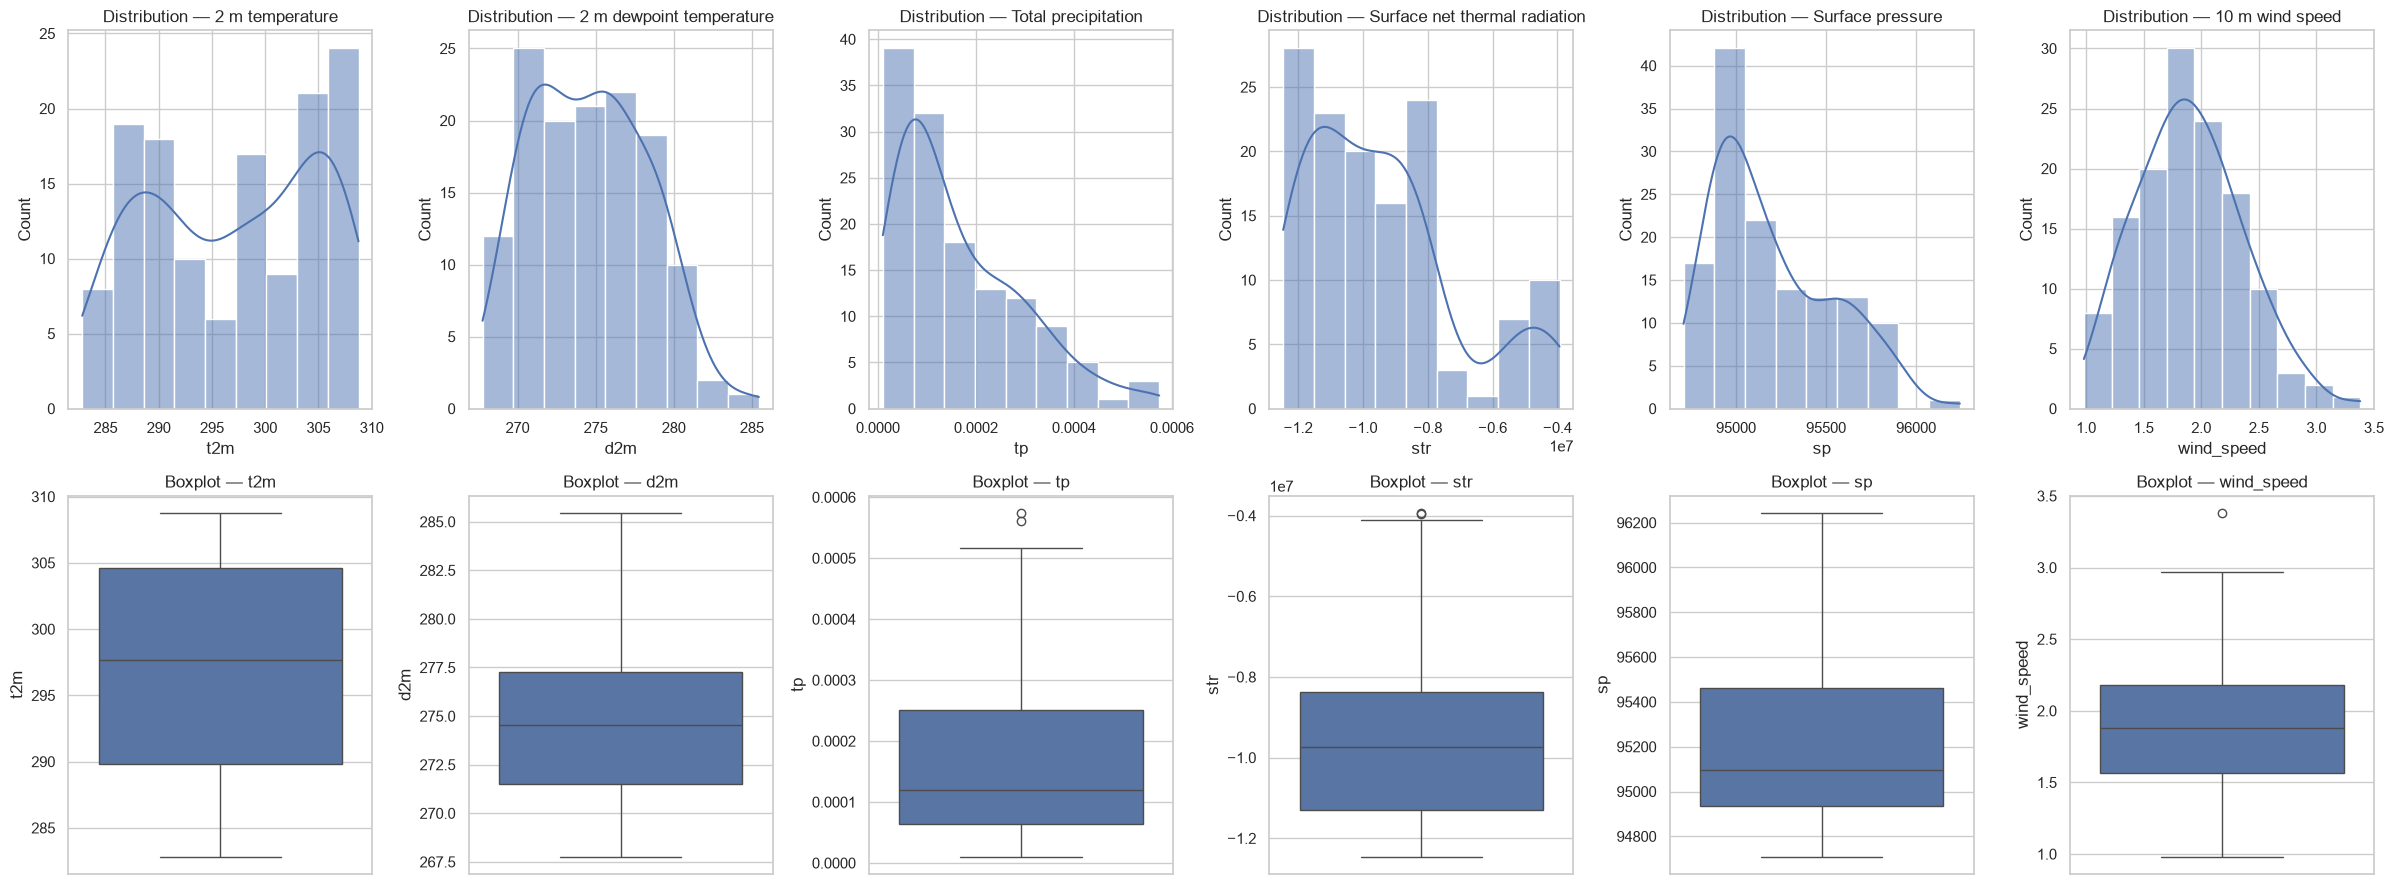

In [18]:
eda_variables = ["t2m", "d2m", "tp", "str", "sp", "wind_speed"]

fig, axes = plt.subplots(2, 6, figsize=(24, 9))

for index, variable in enumerate(eda_variables):

    data = monthly_summary[variable].dropna()

    # Histogramme
    sns.histplot(data, kde=True, ax=axes[0, index])
    axes[0, index].set_title(
        f"Distribution — {VAR_LABELS.get(variable, variable)}"
    )

    # Boxplot
    sns.boxplot(y=data, ax=axes[1, index])
    axes[1, index].set_title(f"Boxplot — {variable}")

plt.tight_layout()
plt.show()

## 1.5 Analyse temporelle : Temperature, Precipitation et Wind

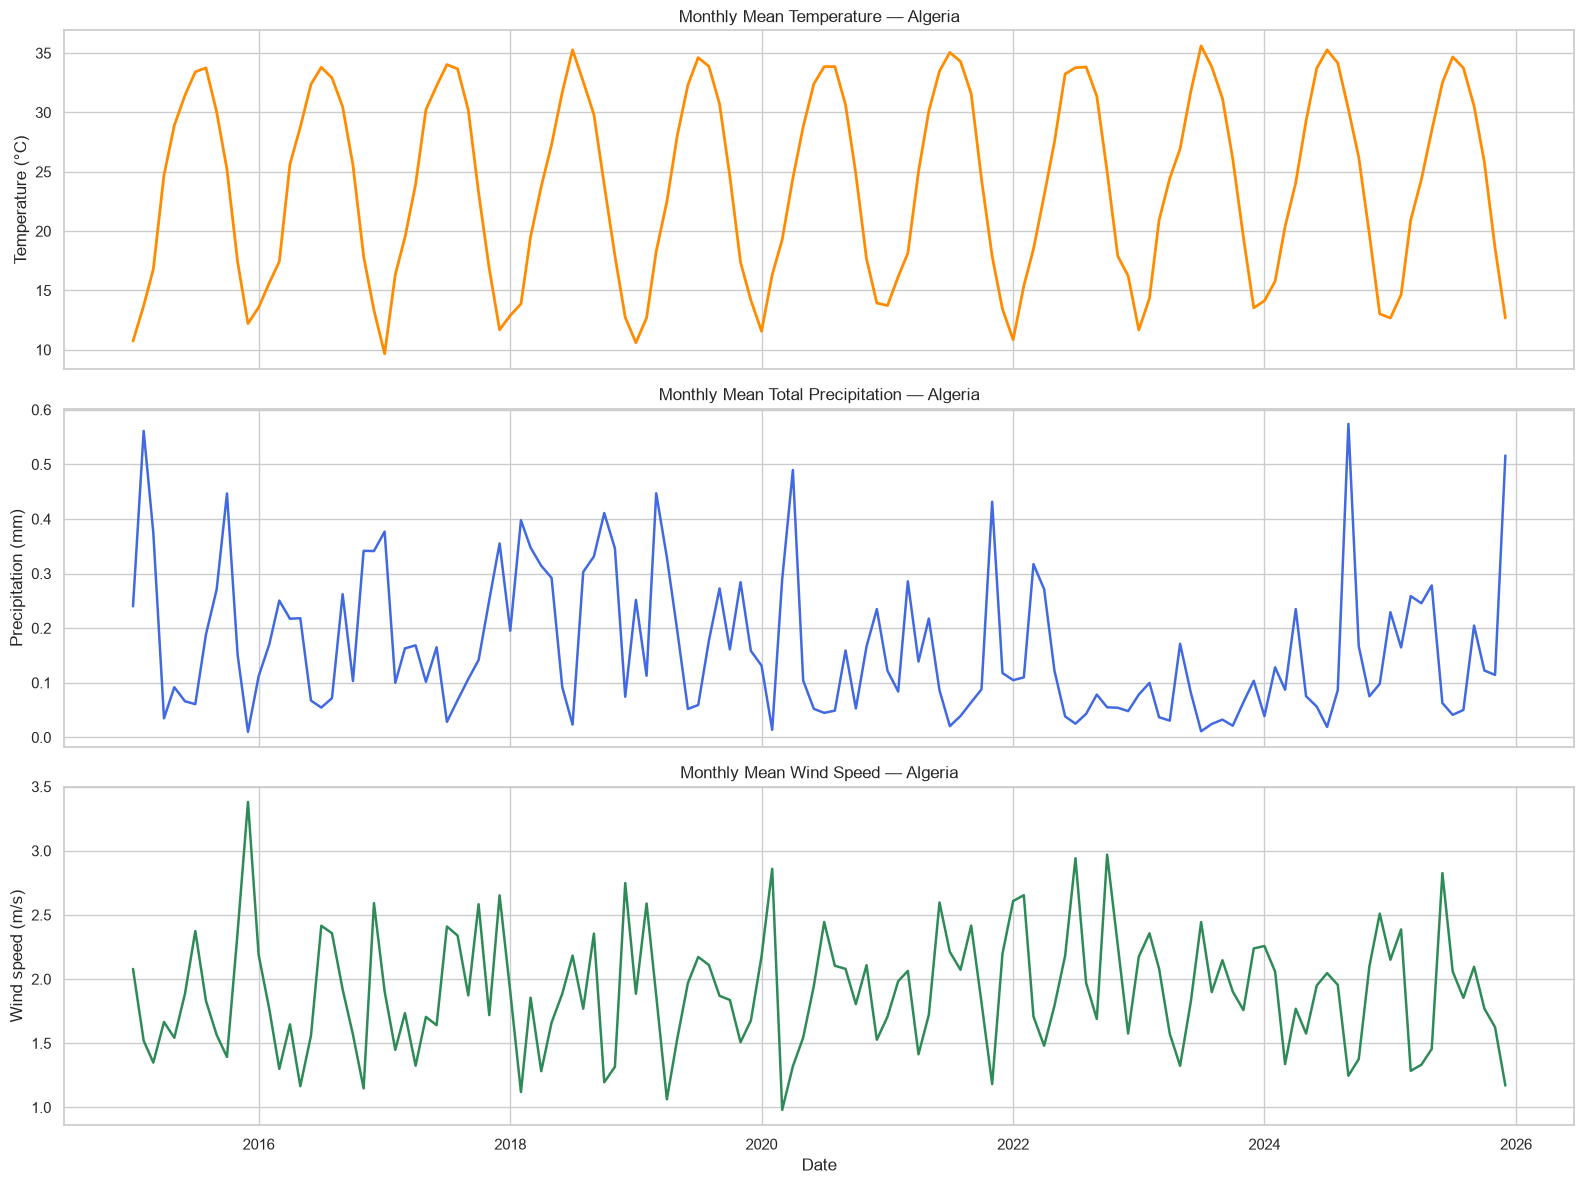

In [19]:
fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

# Température : Kelvin vers Celsius si nécessaire
t2m_units = str(coarse_ds["t2m"].attrs.get("units", "K")).lower()
temperature_series = monthly_summary["t2m"]
if t2m_units in {"k", "kelvin"}:
    temperature_series = temperature_series - 273.15

axes[0].plot(
    monthly_summary.index, temperature_series,
    color="darkorange", linewidth=2
)
axes[0].set_title("Monthly Mean Temperature — Algeria")
axes[0].set_ylabel("Temperature (°C)")

# Précipitations : mètres vers millimètres si nécessaire
tp_units = str(coarse_ds["tp"].attrs.get("units", "m")).lower()
precip_factor = 1000 if tp_units in {"m", "meter", "metre"} else 1
axes[1].plot(
    monthly_summary.index, monthly_summary["tp"] * precip_factor,
    color="royalblue", linewidth=1.8
)
axes[1].set_title("Monthly Mean Total Precipitation — Algeria")
axes[1].set_ylabel("Precipitation (mm)")

axes[2].plot(
    monthly_summary.index, monthly_summary["wind_speed"],
    color="seagreen", linewidth=1.8
)
axes[2].set_title("Monthly Mean Wind Speed — Algeria")
axes[2].set_ylabel("Wind speed (m/s)")
axes[2].set_xlabel("Date")

plt.tight_layout()
plt.show()

## 1.6 Analyse saisonnière : Seasonal Boxplots

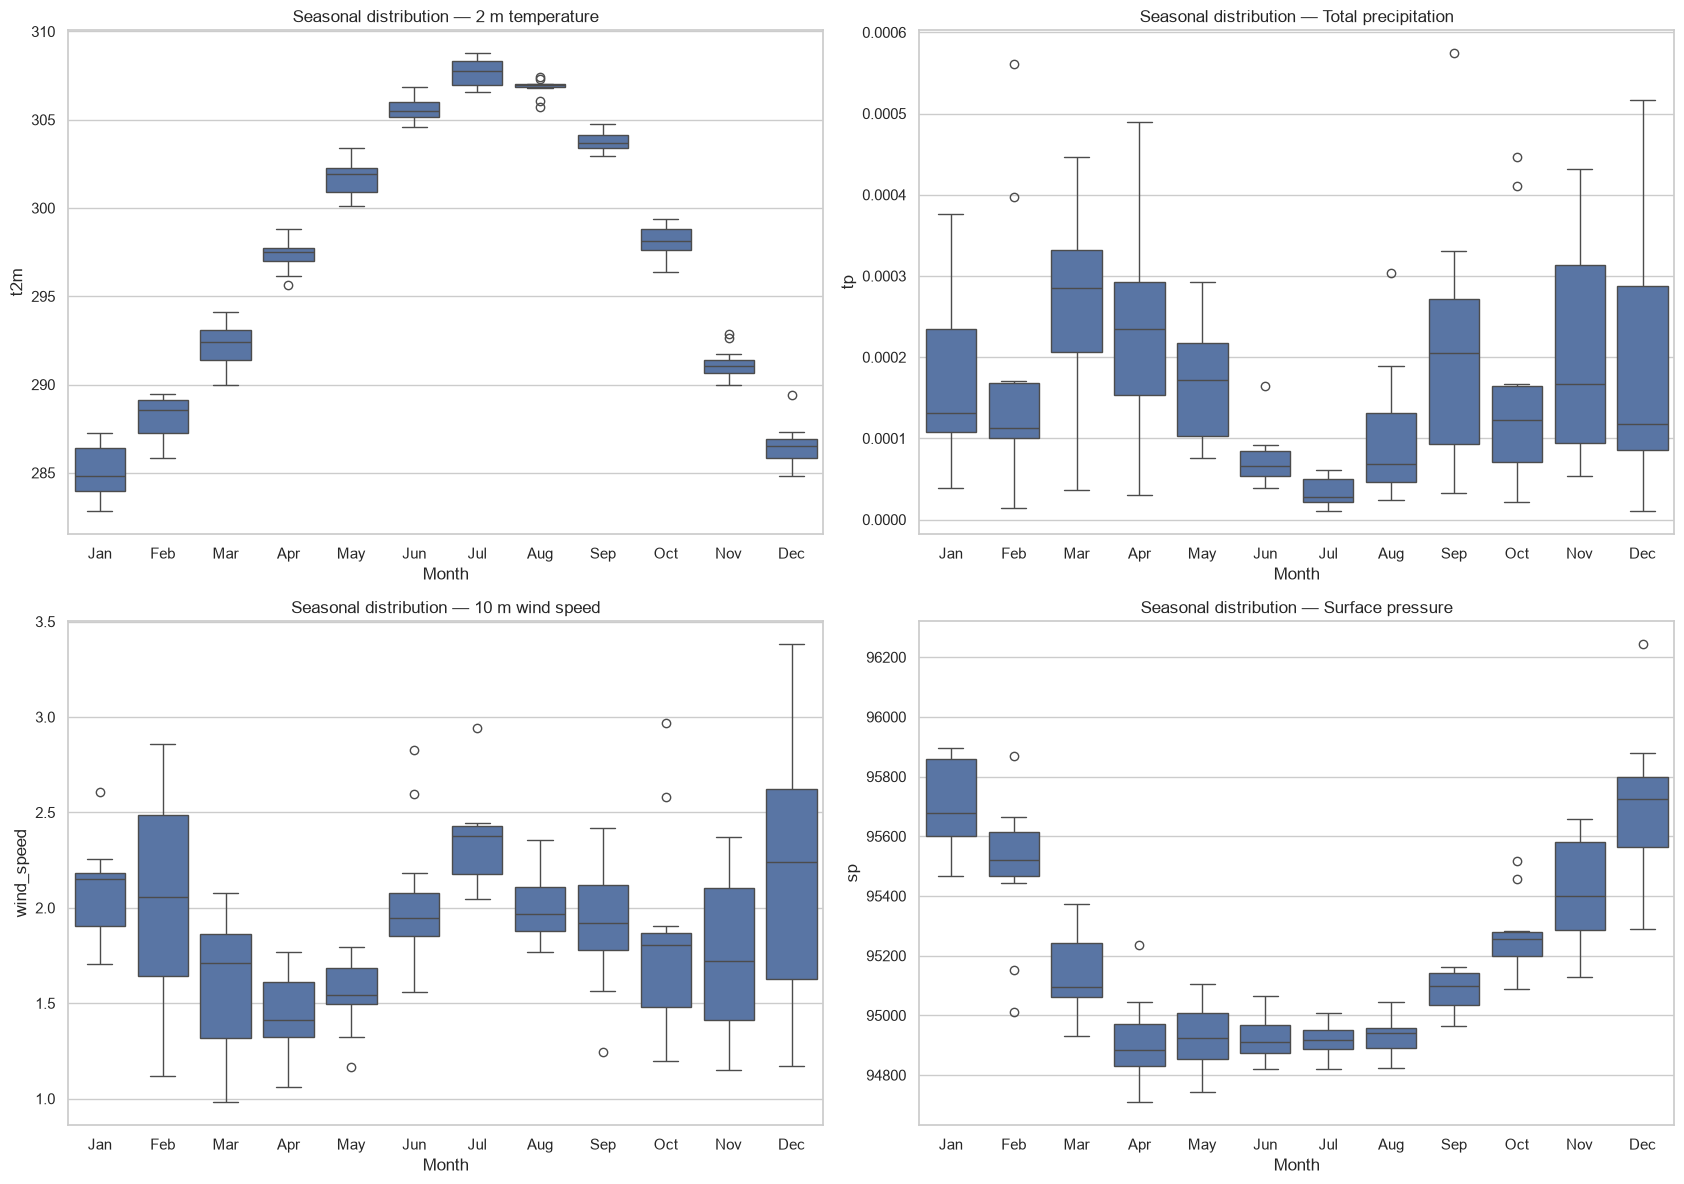

In [20]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

seasonal_data = monthly_summary.reset_index()
seasonal_variables = ["t2m", "tp", "wind_speed", "sp"]

fig, axes = plt.subplots(2, 2, figsize=(17, 12))
for ax, variable in zip(axes.flat, seasonal_variables):
    sns.boxplot(
        data=seasonal_data, x="month", y=variable,
        order=list(range(1, 13)), ax=ax
    )
    ax.set_title(f"Seasonal distribution — {VAR_LABELS.get(variable, variable)}")
    ax.set_xlabel("Month")
    ax.set_xticks(range(12))
    ax.set_xticklabels(month_names)
    ax.set_ylabel(variable)

plt.tight_layout()
plt.show()

## 1.7 Seasonality Heatmap : Year × Month

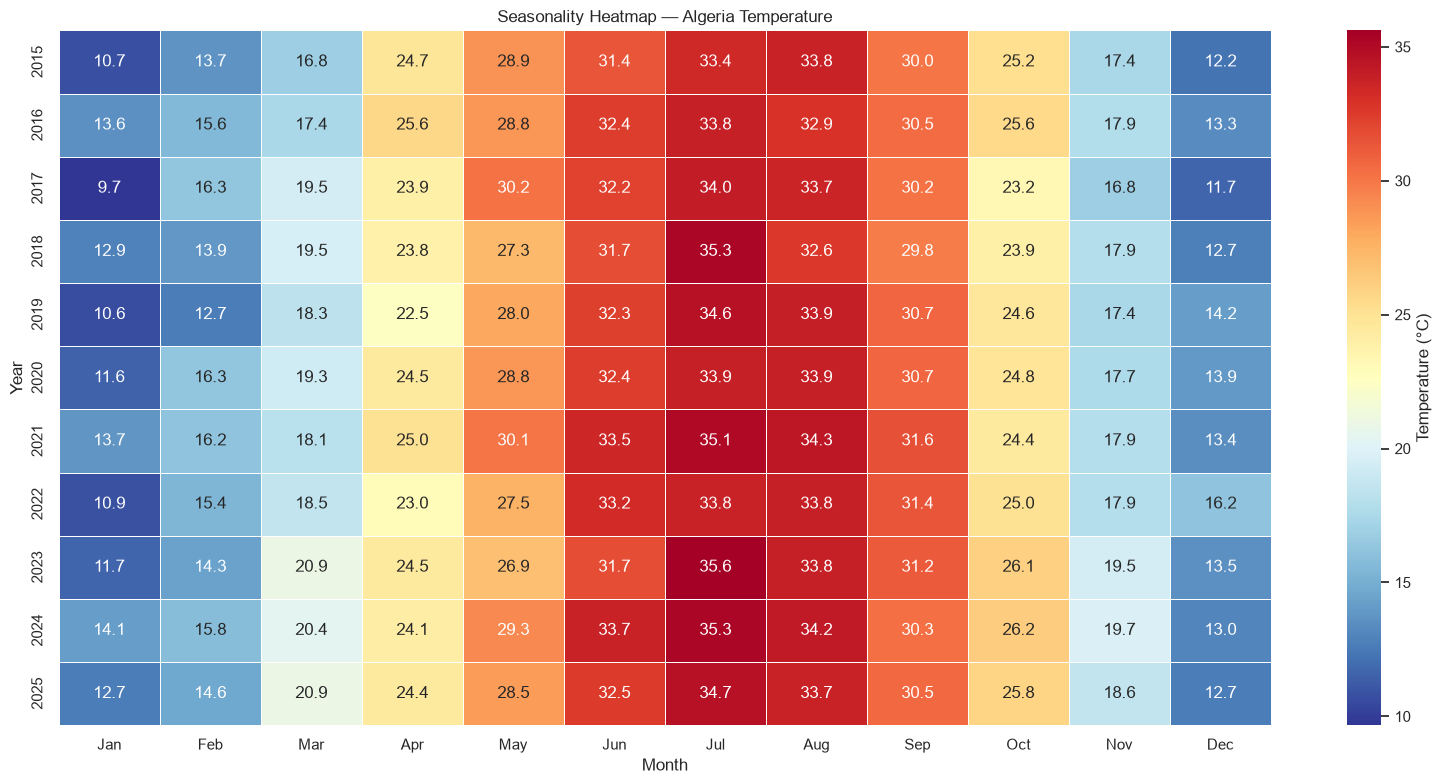

In [21]:
heatmap_data = monthly_summary.pivot_table(
    index="year", columns="month", values="t2m", aggfunc="mean"
).reindex(columns=range(1, 13))

# Conversion en °C pour la lecture de la carte si les données sont en Kelvin
if t2m_units in {"k", "kelvin"}:
    heatmap_data = heatmap_data - 273.15

heatmap_data.columns = month_names
plt.figure(figsize=(16, 8))
sns.heatmap(
    heatmap_data, cmap="RdYlBu_r", annot=True, fmt=".1f",
    linewidths=0.5, cbar_kws={"label": "Temperature (°C)"}
)
plt.title("Seasonality Heatmap — Algeria Temperature")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

## 1.8 Spatial Maps : Geographic Distribution

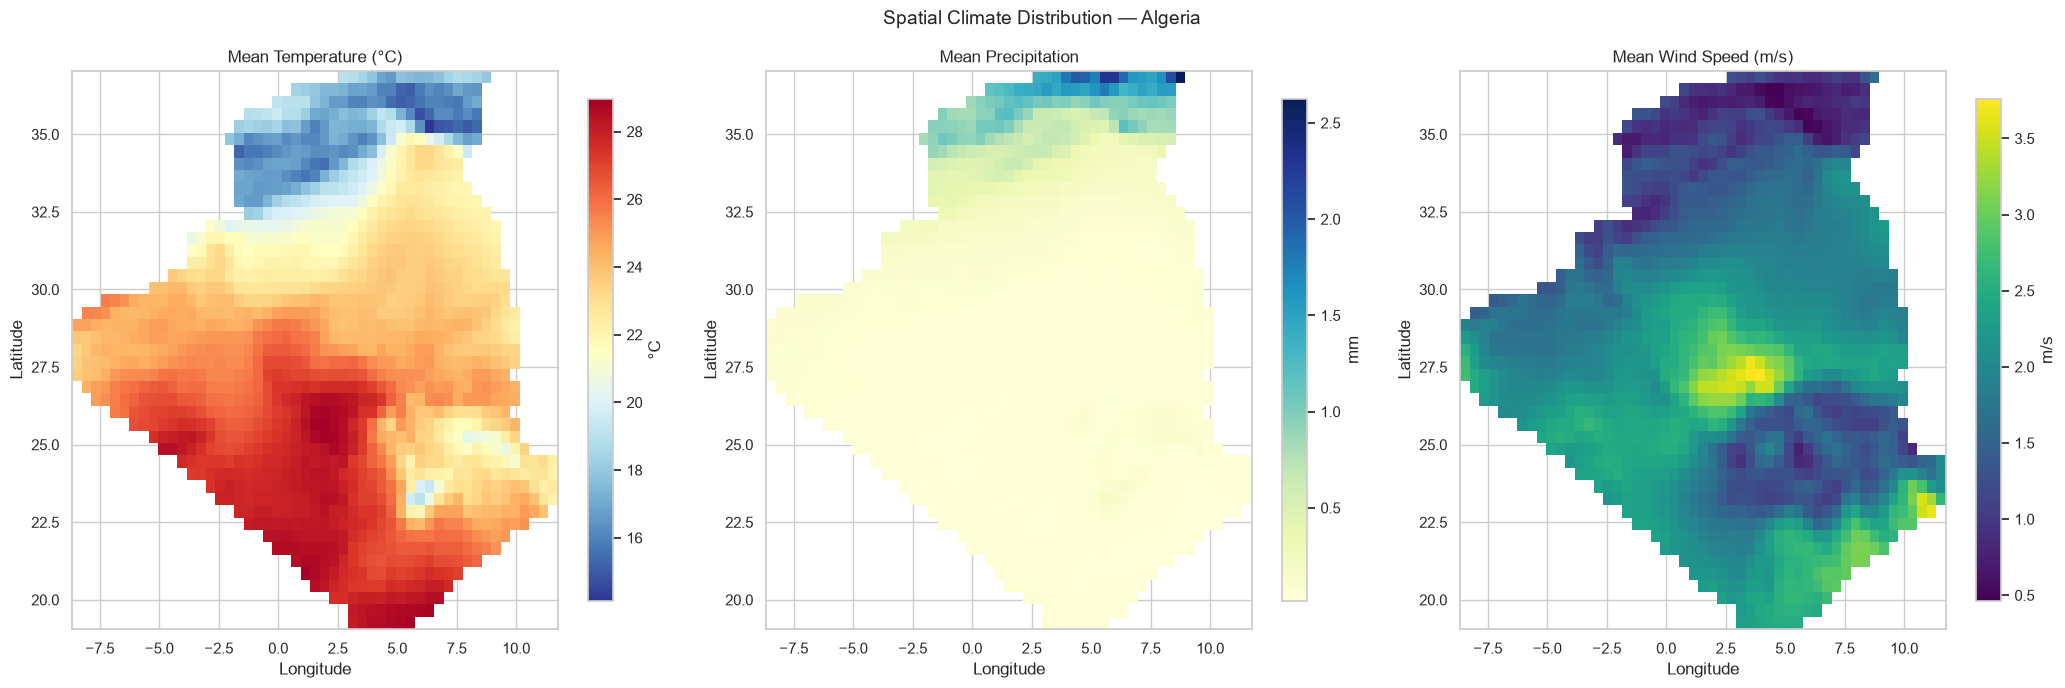

In [22]:
map_variables = [
    ("t2m", "Mean Temperature (°C)", "RdYlBu_r"),
    ("tp", "Mean Precipitation", "YlGnBu"),
    ("wind_speed", "Mean Wind Speed (m/s)", "viridis")
]
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for ax, (variable, title, cmap) in zip(axes, map_variables):
    mean_da = coarse_ds[variable].mean(dim=time_name, skipna=True)
    if variable == "t2m" and str(coarse_ds[variable].attrs.get("units", "K")).lower() in {"k", "kelvin"}:
        mean_da = mean_da - 273.15
        units = "°C"
    elif variable == "tp":
        units_raw = str(coarse_ds[variable].attrs.get("units", "m")).lower()
        if units_raw in {"m", "meter", "metre"}:
            mean_da = mean_da * 1000
            units = "mm"
        else:
            units = coarse_ds[variable].attrs.get("units", "")
    else:
        units = "m/s"
    mesh = ax.pcolormesh(coarse_ds[lon_name], coarse_ds[lat_name], mean_da,
                         shading="auto", cmap=cmap)
    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    fig.colorbar(mesh, ax=ax, shrink=0.9, label=units)
plt.suptitle("Spatial Climate Distribution — Algeria", fontsize=14)
plt.tight_layout()
plt.show()

## 1.9 Correlation Matrix

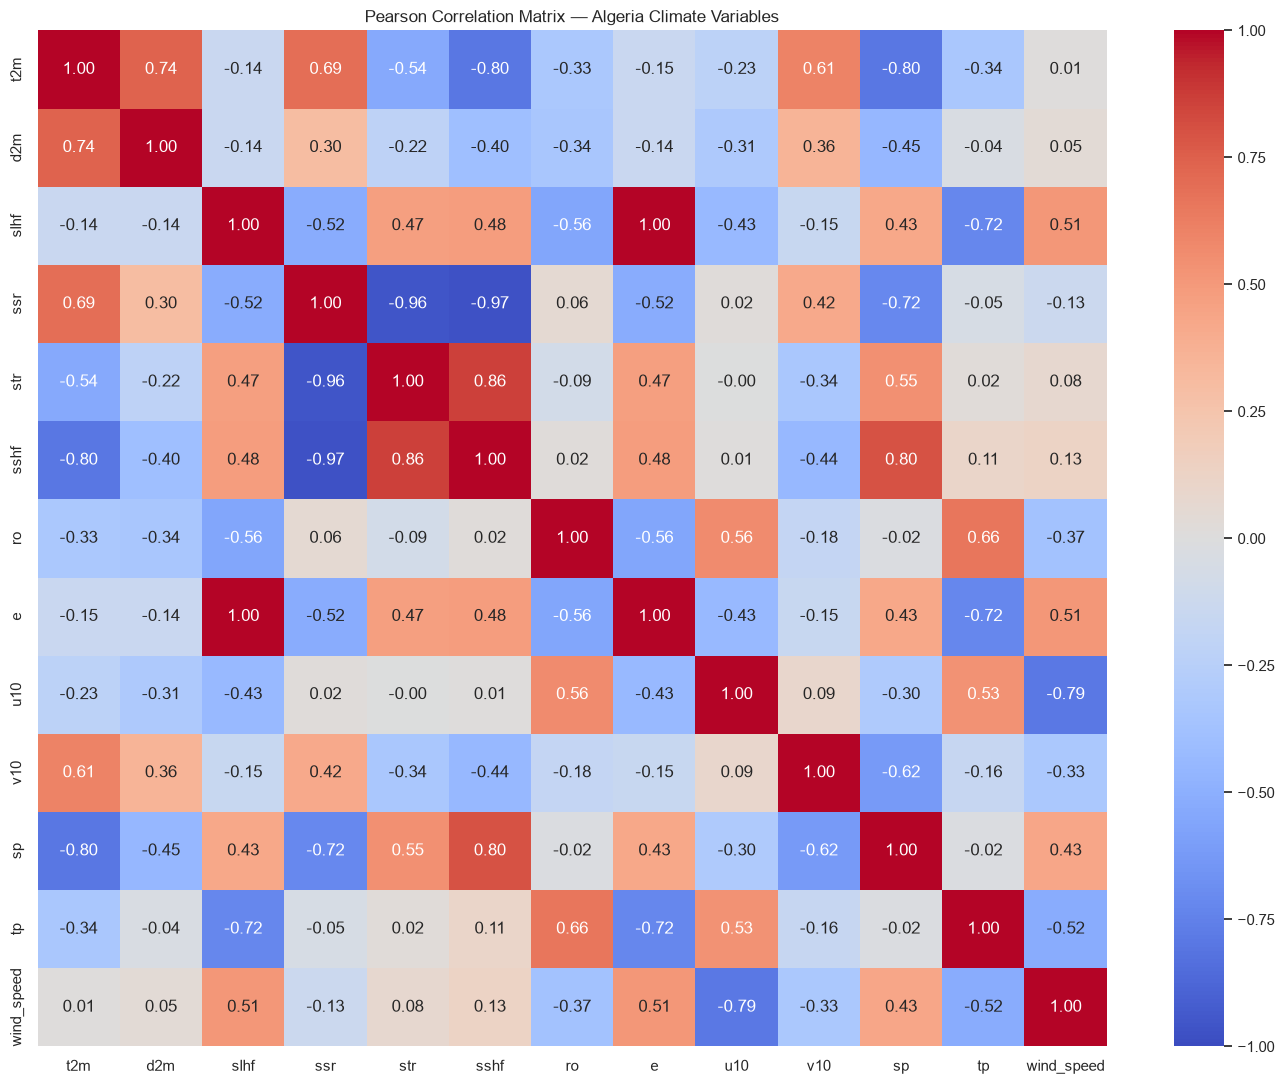

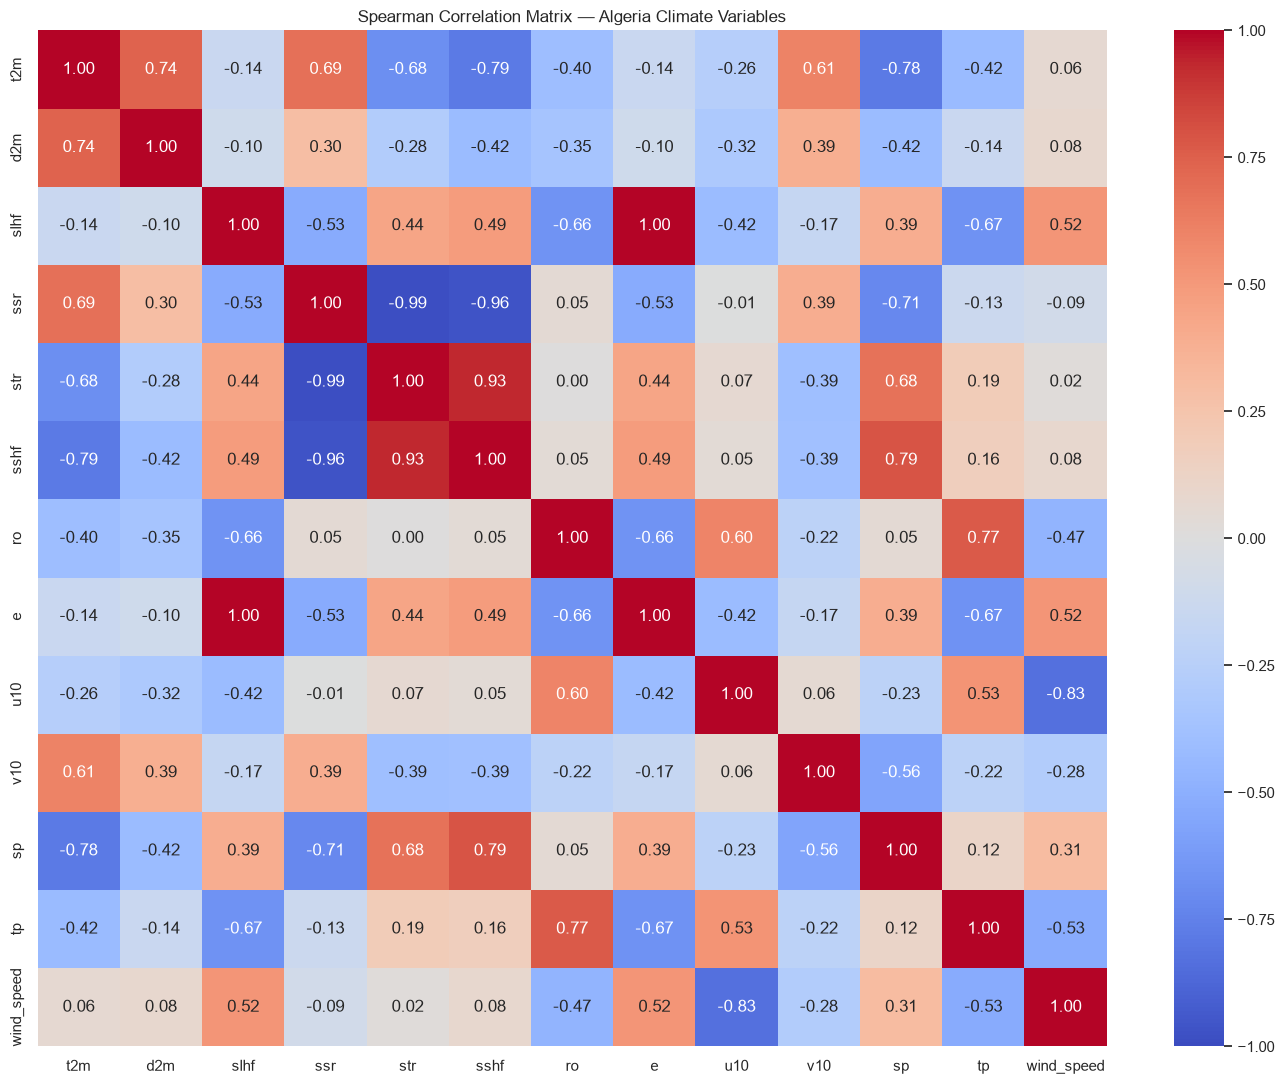

In [23]:
correlation_variables = [v for v in REQUIRED_VARS + ["wind_speed"] if v in monthly_summary]
for method in ["pearson", "spearman"]:
    corr = monthly_summary[correlation_variables].corr(method=method)
    plt.figure(figsize=(14, 11))
    sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f")
    plt.title(f"{method.title()} Correlation Matrix — Algeria Climate Variables")
    plt.tight_layout()
    plt.show()

## 1.10 Scatter Plots : Relationships Between Variables

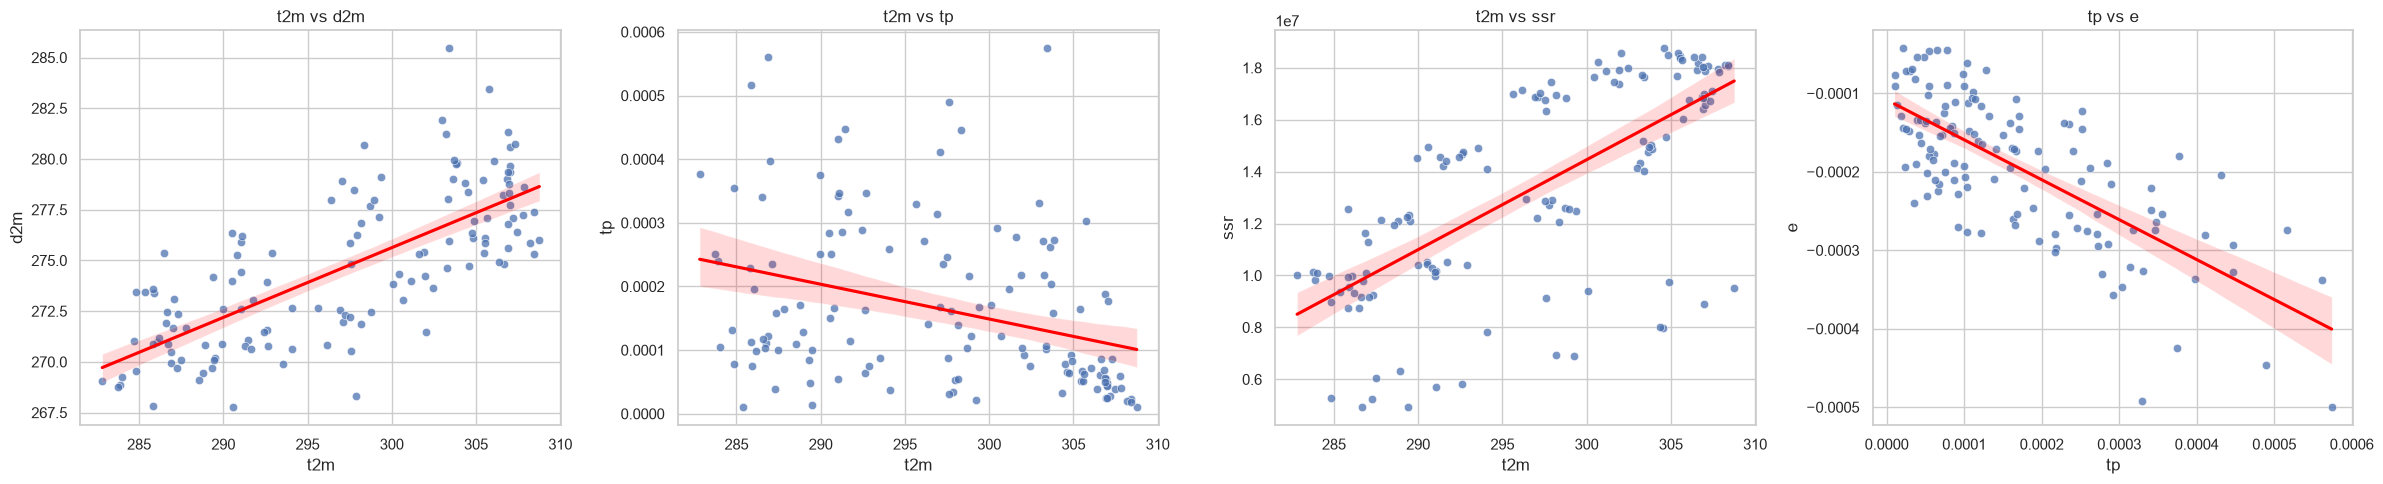

In [24]:
scatter_pairs = [
    ("t2m", "d2m"),
    ("t2m", "tp"),
    ("t2m", "ssr"),
    ("tp", "e")
]
scatter_pairs = [
    (x, y) for x, y in scatter_pairs
    if x in monthly_summary.columns and y in monthly_summary.columns
]

fig, axes = plt.subplots(
    1, len(scatter_pairs),
    figsize=(6 * max(len(scatter_pairs), 1), 5)
)
axes = np.atleast_1d(axes)

for ax, (x, y) in zip(axes, scatter_pairs):
    sns.scatterplot(data=monthly_summary, x=x, y=y, ax=ax, alpha=0.75)
    sns.regplot(
        data=monthly_summary, x=x, y=y, ax=ax,
        scatter=False, color="red"
    )
    ax.set_title(f"{x} vs {y}")

plt.tight_layout()
plt.show()

## 1.11 Data Cleaning : Missing Values et Outliers

In [25]:
# Tableau spatio-temporel après agrégation ×4
spatial_data = coarse_ds[REQUIRED_VARS + ["wind_speed"]].to_dataframe().reset_index()
spatial_data = spatial_data.drop(columns=["number", "expver"], errors="ignore")
spatial_data = spatial_data.dropna(subset=[TARGET_VAR]).copy()
spatial_data[time_name] = pd.to_datetime(spatial_data[time_name])
spatial_data = spatial_data.drop_duplicates(subset=[time_name, lat_name, lon_name])
spatial_data = spatial_data.sort_values([lat_name, lon_name, time_name]).reset_index(drop=True)

missing_report = pd.DataFrame({
    "Missing count": spatial_data.isna().sum(),
    "Missing (%)": spatial_data.isna().mean() * 100
}).sort_values("Missing (%)", ascending=False)

outlier_rows = []
for variable in REQUIRED_VARS + ["wind_speed"]:
    values = spatial_data[variable].dropna()
    if values.empty:
        continue
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((values < lower) | (values > upper)).sum())
    outlier_rows.append({"Variable": variable, "Q1": q1, "Q3": q3, "IQR": iqr,
                         "Lower bound": lower, "Upper bound": upper,
                         "Outlier count": count, "Outlier (%)": 100 * count / len(values)})
missing_report.to_csv(RESULTS_DIR / "missing_values_report.csv")
outlier_report = pd.DataFrame(outlier_rows)
display(missing_report.round(3))
display(outlier_report.round(3))
# Les outliers climatiques ne sont pas supprimés automatiquement : ils peuvent être réels.

,Missing count,Missing (%)
valid_time,0,0.0
latitude,0,0.0
longitude,0,0.0
t2m,0,0.0
d2m,0,0.0
slhf,0,0.0
ssr,0,0.0
str,0,0.0
sshf,0,0.0
ro,0,0.0


,Variable,Q1,Q3,IQR,Lower bound,Upper bound,Outlier count,Outlier (%)
0,t2m,2.894330e+02,3.046870e+02,15.254,2.665530e+02,3.275670e+02,0,0.000
1,d2m,2.713510e+02,2.777800e+02,6.429,2.617080e+02,2.874230e+02,2223,1.194
2,slhf,-3.124629e+05,-8.553908e+04,226923.797,-6.528486e+05,2.548466e+05,30971,16.640
3,ssr,9.983269e+06,1.679614e+07,6812871.750,-2.360384e+05,2.701545e+07,0,0.000
4,str,-1.155006e+07,-7.822465e+06,3727592.875,-1.714145e+07,-2.231076e+06,2,0.001
5,sshf,-4.637632e+06,-1.806228e+06,2831403.844,-8.884738e+06,2.440878e+06,1499,0.805
6,ro,0.000000e+00,0.000000e+00,0.000,-0.000000e+00,0.000000e+00,30510,16.393
7,e,-0.000000e+00,-0.000000e+00,0.000,-0.000000e+00,0.000000e+00,30970,16.640
8,u10,-2.125000e+00,7.200000e-02,2.197,-5.421000e+00,3.368000e+00,1219,0.655
9,v10,-1.162000e+00,2.050000e-01,1.367,-3.213000e+00,2.255000e+00,1903,1.022


## 1.12 Feature Engineering : Target du mois suivant

In [26]:
spatial_data["month"] = spatial_data[time_name].dt.month
spatial_data["year"] = spatial_data[time_name].dt.year
location_columns = [lat_name, lon_name]
spatial_data = spatial_data.sort_values(location_columns + [time_name]).copy()
grouped = spatial_data.groupby(location_columns, sort=False)
spatial_data["target_temp"] = grouped[TARGET_VAR].shift(-1)
spatial_data["target_date"] = grouped[time_name].shift(-1)
current_period = spatial_data[time_name].dt.to_period("M")
next_period = pd.to_datetime(spatial_data["target_date"]).dt.to_period("M")
consecutive = (next_period - current_period).apply(lambda x: x.n == 1 if pd.notna(x) else False)
spatial_data.loc[~consecutive, ["target_temp", "target_date"]] = np.nan
model_data = spatial_data.dropna(subset=["target_temp", "target_date"]).copy()
model_data = model_data.sort_values([time_name, lat_name, lon_name]).reset_index(drop=True)
print("Observations supervisées :", len(model_data))
print("Période :", model_data[time_name].min(), "→", model_data[time_name].max())
display(model_data.head())

Observations supervisées : 184710
Période : 2015-01-01 00:00:00 → 2025-11-01 00:00:00


,valid_time,latitude,longitude,t2m,d2m,slhf,ssr,str,sshf,ro,e,u10,v10,sp,tp,wind_speed,month,year,target_temp,target_date
0,2015-01-01,19.25,3.15,288.912201,265.547607,-55218.000000,11171371.0,-9554721.0,-1776237.750,0.0,-0.000022,-3.425352,-2.353876,96085.164062,0.000001,4.156173,1,2015,294.456543,2015-02-01
1,2015-01-01,19.25,3.55,289.053345,265.644897,-55976.625000,11331794.0,-9614744.0,-1879490.625,0.0,-0.000022,-3.518322,-2.341682,96361.687500,0.000001,4.226354,1,2015,294.713867,2015-02-01
2,2015-01-01,19.25,3.95,289.227539,265.746552,-56668.132812,11462752.0,-9675262.0,-1950865.625,0.0,-0.000023,-3.590219,-2.445859,96562.875000,0.000001,4.344180,1,2015,294.974762,2015-02-01
3,2015-01-01,19.25,4.35,289.274658,265.868408,-56709.667969,11398013.0,-9691476.0,-1870190.500,0.0,-0.000023,-3.630820,-2.655902,96786.125000,0.000001,4.498518,1,2015,294.928223,2015-02-01
4,2015-01-01,19.25,4.75,289.386230,265.986572,-56617.750000,11353064.0,-9726184.0,-1791058.500,0.0,-0.000023,-3.699200,-2.851418,96970.625000,0.000001,4.670617,1,2015,294.968262,2015-02-01


# PARTIE 2 — SUPERVISED MACHINE LEARNING

## 2.1 Discrétisation de la température et séparation Train/Test

La température `t2m` du mois suivant est transformée en trois classes par **Equal-Width Discretization** :
- Classe 0 : Froide
- Classe 1 : Modérée
- Classe 2 : Chaude

Le découpage Train/Test respecte l'ordre chronologique : 80 % pour l'entraînement et 20 % pour le test. Les seuils de discrétisation sont appris uniquement sur les cibles d'entraînement afin d'éviter une fuite d'information.

In [27]:
unique_dates = np.sort(model_data[time_name].dropna().unique())
if len(unique_dates) < 6:
    raise ValueError("Nombre de mois insuffisant pour effectuer un découpage chronologique.")
split_position = int(len(unique_dates) * (1 - TEST_SIZE))
split_position = min(max(split_position, 2), len(unique_dates) - 2)
split_date = pd.Timestamp(unique_dates[split_position])

# Purge : les étiquettes d'entraînement doivent être connues avant la période de test.
train_data = model_data[model_data["target_date"] < split_date].copy()
test_data = model_data[model_data[time_name] >= split_date].copy()
if train_data.empty or test_data.empty:
    raise ValueError("Train/Test vide après séparation temporelle.")

# Equal-width discretization : 3 intervalles de même largeur, bornes calculées sur Train.
target_min, target_max = train_data["target_temp"].min(), train_data["target_temp"].max()
if np.isclose(target_min, target_max):
    raise ValueError("La température cible est constante.")
inner_edges = np.linspace(target_min, target_max, N_CLASSES + 1)[1:-1]
bin_edges = np.r_[-np.inf, inner_edges, np.inf]
train_data["target_class"] = pd.cut(train_data["target_temp"], bins=bin_edges, labels=False, include_lowest=True)
test_data["target_class"] = pd.cut(test_data["target_temp"], bins=bin_edges, labels=False, include_lowest=True)
train_data = train_data.dropna(subset=["target_class"]).copy()
test_data = test_data.dropna(subset=["target_class"]).copy()
y_train = train_data["target_class"].astype(int)
y_test = test_data["target_class"].astype(int)
print("Date de séparation :", split_date)
print("Train brut :", len(train_data), "| Test :", len(test_data))
print("Bornes des classes :", bin_edges)
display(y_train.value_counts().sort_index().rename(index=dict(enumerate(CLASS_NAMES))))

Date de séparation : 2023-09-01 00:00:00
Train brut : 145230 | Test : 38070
Bornes des classes : [     -inf 287.83908 300.98123       inf]


target_class
Froide     27269
Modérée    61347
Chaude     56614
Name: count, dtype: int64

## 2.2 K-Nearest Neighbors, SVM et Random Forest

In [28]:
# Variables explicatives prescrites : 11 variables climatiques + mois + année.
feature_columns = SUPERVISED_FEATURES + ["month", "year"]
X_train_full = train_data[feature_columns].replace([np.inf, -np.inf], np.nan)
X_test = test_data[feature_columns].replace([np.inf, -np.inf], np.nan)
usable_features = [c for c in feature_columns if X_train_full[c].notna().any()]
X_train_full, X_test = X_train_full[usable_features], X_test[usable_features]

# Échantillonnage stratifié du TRAIN uniquement pour limiter le coût mémoire/temps sur PC 8 Go.
if len(X_train_full) > MAX_SUPERVISED_TRAIN:
    train_with_class = train_data.copy()
    train_with_class["_class"] = y_train.values
    sampled_parts = []
    for class_id, group in train_with_class.groupby("_class"):
        n_class = max(1, round(MAX_SUPERVISED_TRAIN * len(group) / len(train_with_class)))
        sampled_parts.append(group.sample(n=min(n_class, len(group)), random_state=RANDOM_STATE))
    train_sample = pd.concat(sampled_parts).sample(frac=1, random_state=RANDOM_STATE)
    if len(train_sample) > MAX_SUPERVISED_TRAIN:
        train_sample = train_sample.sample(MAX_SUPERVISED_TRAIN, random_state=RANDOM_STATE)
    X_train = train_sample[usable_features].replace([np.inf, -np.inf], np.nan)
    y_train_fit = train_sample["_class"].astype(int)
else:
    X_train, y_train_fit = X_train_full, y_train

print("X_train :", X_train.shape, "| X_test :", X_test.shape)
print("Features :", usable_features)

def scaled_pipeline(estimator):
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler()), ("model", estimator)])

def unscaled_pipeline(estimator):
    return Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", estimator)])

models = {
    "KNN": scaled_pipeline(KNeighborsClassifier(n_neighbors=7, n_jobs=-1)),
    # probability=True est nécessaire pour le Soft Voting manuel ci-dessous.
    "SVM": scaled_pipeline(SVC(kernel="rbf", C=10, gamma="scale", probability=True,
                                random_state=RANDOM_STATE, cache_size=500)),
    "Random Forest": unscaled_pipeline(RandomForestClassifier(
        n_estimators=150, max_depth=None, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1))
}
predictions, probabilities, fit_times = {}, {}, {}
for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train_fit)
    fit_times[name] = time.time() - start
    predictions[name] = model.predict(X_test)
    probabilities[name] = model.predict_proba(X_test)
    print(f"{name} trained in {fit_times[name]:.1f} s")

X_train : (40000, 13) | X_test : (38070, 13)
Features : ['d2m', 'slhf', 'ssr', 'str', 'sshf', 'ro', 'e', 'u10', 'v10', 'sp', 'tp', 'month', 'year']
KNN trained in 0.3 s
SVM trained in 92.8 s
Random Forest trained in 4.4 s


## 2.3 Ensemble Learning : Hard Voting, Soft Voting et AdaBoost

In [29]:
# Hard Voting : vote majoritaire des prédictions des trois modèles de base.
base_names = ["KNN", "SVM", "Random Forest"]
pred_matrix = np.column_stack([predictions[n] for n in base_names])
predictions["Hard Voting"] = np.array([
    np.bincount(row.astype(int), minlength=N_CLASSES).argmax() for row in pred_matrix
])

# Soft Voting : moyenne des probabilités, colonnes alignées sur les classes 0,1,2.
proba_aligned = []
for name in base_names:
    estimator = models[name].named_steps["model"]
    aligned = np.zeros((len(X_test), N_CLASSES))
    for j, cls in enumerate(estimator.classes_):
        aligned[:, int(cls)] = probabilities[name][:, j]
    proba_aligned.append(aligned)
predictions["Soft Voting"] = np.mean(proba_aligned, axis=0).argmax(axis=1)

ada = unscaled_pipeline(AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE),
    n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE
))
start = time.time()
ada.fit(X_train, y_train_fit)
fit_times["AdaBoost"] = time.time() - start
models["AdaBoost"] = ada
predictions["AdaBoost"] = ada.predict(X_test)
print("Hard Voting, Soft Voting et AdaBoost terminés.")

Hard Voting, Soft Voting et AdaBoost terminés.


## 2.4 Evaluation : Accuracy, Precision, Recall et F1-score

In [30]:
results = []
for name, pred in predictions.items():
    cm = confusion_matrix(y_test, pred, labels=list(range(N_CLASSES)))
    # Specificity calculée en one-vs-rest, puis macro-moyennée.
    specificities = []
    for class_id in range(N_CLASSES):
        tp = cm[class_id, class_id]
        fn = cm[class_id, :].sum() - tp
        fp = cm[:, class_id].sum() - tp
        tn = cm.sum() - tp - fn - fp
        specificities.append(tn / (tn + fp) if (tn + fp) else np.nan)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "Specificity macro": float(np.nanmean(specificities)),
        "F1 macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "MCC": matthews_corrcoef(y_test, pred),
        "Fit time (s)": fit_times.get(name, np.nan)
    })
supervised_results = pd.DataFrame(results).sort_values("F1 macro", ascending=False).reset_index(drop=True)
display(supervised_results.round(4))
supervised_results.to_csv(RESULTS_DIR / "supervised_model_comparison.csv", index=False)

,Model,Accuracy,Precision macro,Recall macro,Specificity macro,F1 macro,MCC,Fit time (s)
0,Random Forest,0.8567,0.8632,0.8448,0.9208,0.8530,0.7716,4.3872
1,Soft Voting,0.8287,0.8446,0.8121,0.9037,0.8247,0.7290,NaN
2,Hard Voting,0.8271,0.8325,0.8141,0.9046,0.8214,0.7261,NaN
3,AdaBoost,0.8255,0.8536,0.7746,0.8997,0.7976,0.7226,9.8291
4,KNN,0.7790,0.7747,0.7781,0.8816,0.7760,0.6513,0.3302
5,SVM,0.6374,0.6852,0.6279,0.7951,0.6325,0.4328,92.8234


## 2.5 Confusion Matrices

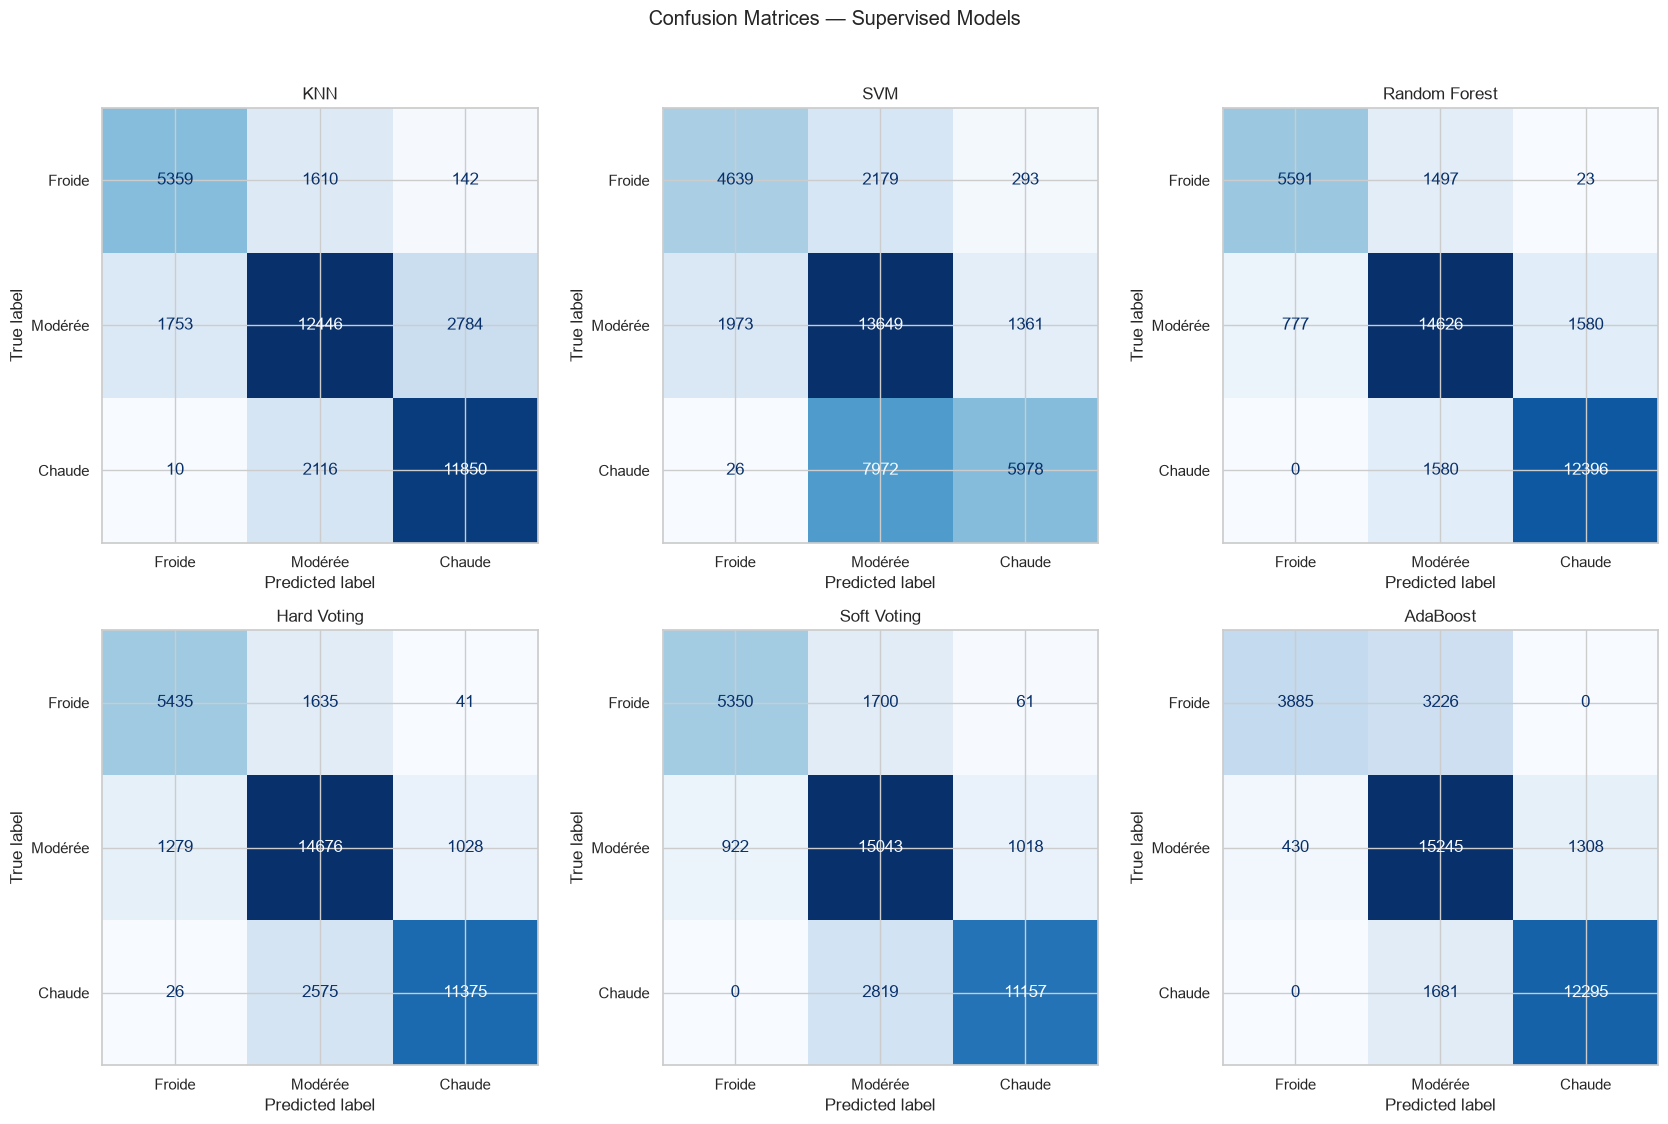

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(17, 11))
for ax, (model_name, y_pred) in zip(axes.flat, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=list(range(N_CLASSES)),
        display_labels=CLASS_NAMES,
        cmap="Blues",
        colorbar=False,
        ax=ax
    )
    ax.set_title(model_name)

# Masquer les axes inutilisés si le nombre de modèles est inférieur à 6
for ax in axes.flat[len(predictions):]:
    ax.set_visible(False)

plt.suptitle("Confusion Matrices — Supervised Models", y=1.02)
plt.tight_layout()
plt.show()

## 2.6 Comparaison graphique des modèles

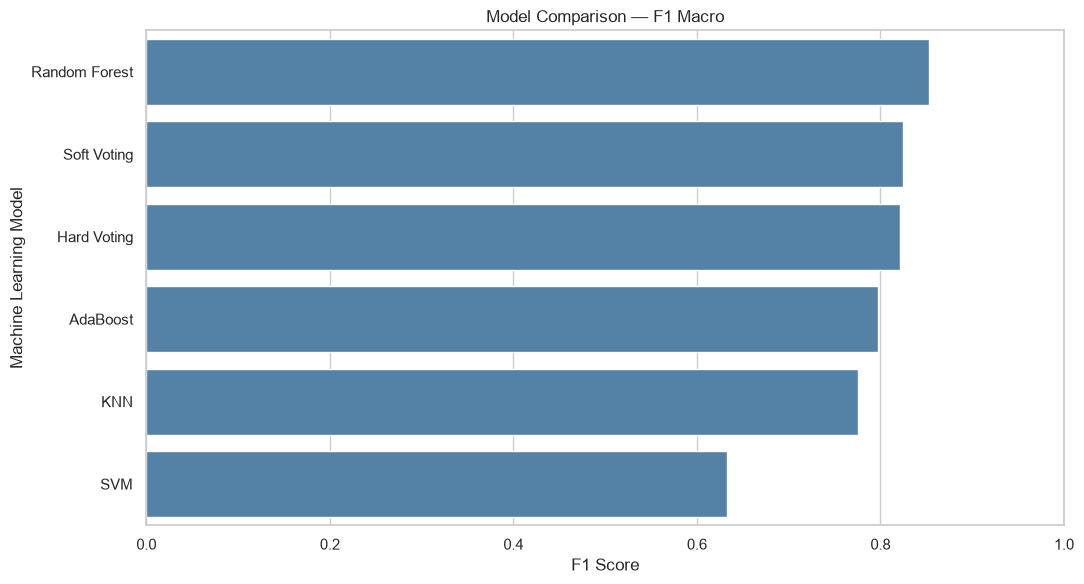

In [32]:
plt.figure(figsize=(11, 6))
sns.barplot(
    data=supervised_results,
    x="F1 macro",
    y="Model",
    color="steelblue"
)
plt.title("Model Comparison — F1 Macro")
plt.xlabel("F1 Score")
plt.ylabel("Machine Learning Model")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

## 2.7 Feature Importance — Random Forest

,Feature,Importance
3,str,0.1775
2,ssr,0.1611
11,month,0.1587
4,sshf,0.1093
1,slhf,0.0677
9,sp,0.0663
6,e,0.0546
0,d2m,0.0448
7,u10,0.0437
12,year,0.0424


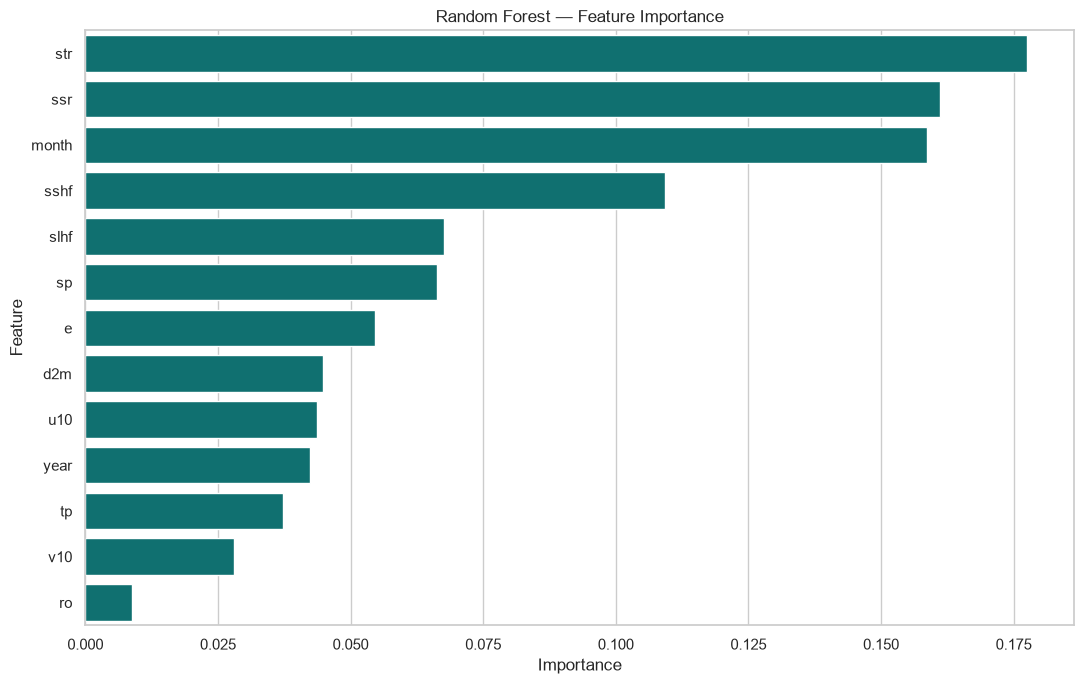

In [33]:
# Extraction du modèle Random Forest entraîné
rf_model = models["Random Forest"].named_steps["model"]

rf_importance = pd.DataFrame({
    "Feature": usable_features,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(rf_importance.round(4))

plt.figure(figsize=(11, 7))
sns.barplot(
    data=rf_importance,
    x="Importance",
    y="Feature",
    color="teal"
)
plt.title("Random Forest — Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 2.8 Exportation des résultats

In [34]:
# Création du dossier results
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Export des analyses exploratoires
overview.to_csv(RESULTS_DIR / "01_dataset_overview.csv", index=False)
desc.to_csv(RESULTS_DIR / "02_descriptive_statistics.csv")
missing_report.to_csv(RESULTS_DIR / "03_missing_values.csv")
outlier_report.to_csv(RESULTS_DIR / "04_outliers_iqr.csv", index=False)

# Export de la comparaison des modèles et de l'importance des variables
supervised_results.to_csv(
    RESULTS_DIR / "05_supervised_model_comparison.csv", index=False
)
rf_importance.to_csv(
    RESULTS_DIR / "06_random_forest_feature_importance.csv", index=False
)

# Export des prédictions du jeu de test
prediction_export = test_data[
    [time_name, "target_date", "target_temp", "target_class"]
].copy().reset_index(drop=True)

for model_name, y_pred in predictions.items():
    prediction_export[model_name] = y_pred

prediction_export.to_csv(
    RESULTS_DIR / "07_test_predictions.csv", index=False
)

print("Export terminé. Fichiers disponibles dans :", RESULTS_DIR.resolve())
print("\n".join(f"- {path.name}" for path in sorted(RESULTS_DIR.glob("*.csv"))))

Export terminé. Fichiers disponibles dans : C:\Users\DELL\Desktop\M2\data mining\results
- 01_dataset_overview.csv
- 02_descriptive_statistics.csv
- 03_missing_values.csv
- 04_outliers_iqr.csv
- 05_supervised_model_comparison.csv
- 06_random_forest_feature_importance.csv
- 07_test_predictions.csv
- missing_values_report.csv
- supervised_model_comparison.csv


# PARTIE 3 — UNSUPERVISED MACHINE LEARNING (CLUSTERING)

Le sujet demande d'utiliser chaque année les profils mensuels de `str` (Surface net thermal radiation) et `t2m` (2-meter temperature), puis de créer des caractéristiques supplémentaires pour suivre les tendances climatiques. Chaque point spatial devient donc une observation décrite par 24 valeurs (12 mois de `str` + 12 mois de `t2m`), auxquelles on ajoute des indicateurs annuels de tendance et de moyenne.

Les algorithmes sont appliqués année par année. AGNES et DBSCAN peuvent être coûteux ; un échantillon spatial plafonné est donc utilisé de manière reproductible lorsque nécessaire.

In [35]:
# Construire une table annuelle : une ligne par cellule spatiale et une colonne par mois/variable.
cluster_source = coarse_ds[["t2m", "str"]].to_dataframe().reset_index()
cluster_source = cluster_source.dropna(subset=["t2m", "str"], how="all")
cluster_source[time_name] = pd.to_datetime(cluster_source[time_name])
cluster_source["year"] = cluster_source[time_name].dt.year
cluster_source["month"] = cluster_source[time_name].dt.month

# Conversion thermique en unités lisibles seulement pour interprétation ; scaling ensuite.
t2m_unit = str(coarse_ds["t2m"].attrs.get("units", "K")).lower()
str_unit = str(coarse_ds["str"].attrs.get("units", "unknown"))
if t2m_unit in {"k", "kelvin"}:
    cluster_source["t2m"] = cluster_source["t2m"] - 273.15

annual_profiles = {}
for year in sorted(cluster_source["year"].dropna().unique()):
    year_df = cluster_source[cluster_source["year"] == year]
    pivot_t = year_df.pivot_table(index=[lat_name, lon_name], columns="month", values="t2m", aggfunc="mean")
    pivot_s = year_df.pivot_table(index=[lat_name, lon_name], columns="month", values="str", aggfunc="mean")
    pivot_t = pivot_t.reindex(columns=range(1, 13))
    pivot_s = pivot_s.reindex(columns=range(1, 13))
    pivot_t.columns = [f"t2m_m{m:02d}" for m in range(1, 13)]
    pivot_s.columns = [f"str_m{m:02d}" for m in range(1, 13)]
    profile = pd.concat([pivot_t, pivot_s], axis=1)
    # Features de tendance inter-mensuelle demandées pour suivre le changement climatique.
    tcols = [f"t2m_m{m:02d}" for m in range(1, 13)]
    scols = [f"str_m{m:02d}" for m in range(1, 13)]
    profile["t2m_annual_mean"] = profile[tcols].mean(axis=1)
    profile["t2m_annual_std"] = profile[tcols].std(axis=1)
    profile["t2m_trend"] = profile[tcols].apply(
        lambda row: np.polyfit(np.arange(1, 13)[row.notna()], row.dropna(), 1)[0]
        if row.notna().sum() >= 3 else np.nan, axis=1)
    profile["str_annual_mean"] = profile[scols].mean(axis=1)
    profile["str_annual_std"] = profile[scols].std(axis=1)
    profile["str_trend"] = profile[scols].apply(
        lambda row: np.polyfit(np.arange(1, 13)[row.notna()], row.dropna(), 1)[0]
        if row.notna().sum() >= 3 else np.nan, axis=1)
    profile = profile.replace([np.inf, -np.inf], np.nan)
    # Retirer les colonnes totalement vides, puis imputer par médiane.
    profile = profile.dropna(axis=1, how="all")
    profile = profile.dropna(axis=0, thresh=max(6, int(profile.shape[1] * 0.5)))
    annual_profiles[int(year)] = profile

print("Années disponibles pour clustering :", list(annual_profiles))
print("Exemple de dimensions :", {y: x.shape for y, x in list(annual_profiles.items())[:3]})

Années disponibles pour clustering : [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
Exemple de dimensions : {2015: (1410, 30), 2016: (1410, 30), 2017: (1410, 30)}


## 3.1 Fonctions de clustering et d'évaluation

Les données sont imputées par médiane et standardisées avant clustering. Les scores Silhouette, Davies–Bouldin et Calinski–Harabasz sont calculés uniquement si le résultat contient au moins deux clusters et moins de clusters que d'observations. Le bruit DBSCAN (`-1`) est exclu de ces scores.

In [36]:
def evaluate_clusters(X_scaled, labels):
    labels = np.asarray(labels)
    unique = set(labels)
    if -1 in unique:
        mask = labels != -1
        X_eval, labels_eval = X_scaled[mask], labels[mask]
    else:
        X_eval, labels_eval = X_scaled, labels
    n_clusters = len(set(labels_eval))
    if n_clusters < 2 or n_clusters >= len(labels_eval):
        return {"n_clusters": len(unique - {-1}), "noise_pct": 100 * np.mean(labels == -1),
                "silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
    return {
        "n_clusters": len(unique - {-1}),
        "noise_pct": 100 * np.mean(labels == -1),
        "silhouette": silhouette_score(X_eval, labels_eval),
        "davies_bouldin": davies_bouldin_score(X_eval, labels_eval),
        "calinski_harabasz": calinski_harabasz_score(X_eval, labels_eval)
    }


def fit_annual_clustering(profile, year):
    # Limiter le coût quadratique de DBSCAN/AGNES sur les ordinateurs à RAM limitée.
    if len(profile) > MAX_CLUSTER_POINTS:
        sample_profile = profile.sample(MAX_CLUSTER_POINTS, random_state=RANDOM_STATE)
    else:
        sample_profile = profile.copy()
    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()
    X_imp = imputer.fit_transform(sample_profile)
    Xs = scaler.fit_transform(X_imp)
    n = len(Xs)
    if n < 5:
        print(f"{year}: trop peu de cellules pour clustering ({n}).")
        return None

    results, labels_by_method = [], {}
    k = min(4, max(2, int(np.sqrt(n / 2))))
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = kmeans.fit_predict(Xs)
    labels_by_method["KMeans"] = labels
    results.append({"year": year, "method": "KMeans", **evaluate_clusters(Xs, labels),
                    "inertia": float(kmeans.inertia_)})

    # DBSCAN : paramètres de départ raisonnables après standardisation ; à discuter/ajuster.
    db = DBSCAN(eps=2.0, min_samples=max(5, int(np.sqrt(n) / 3)), n_jobs=-1)
    db_labels = db.fit_predict(Xs)
    labels_by_method["DBSCAN"] = db_labels
    results.append({"year": year, "method": "DBSCAN", **evaluate_clusters(Xs, db_labels), "inertia": np.nan})

    # AGNES : Ward utilise la distance euclidienne et nécessite des données standardisées.
    ag = AgglomerativeClustering(n_clusters=k, linkage="ward")
    ag_labels = ag.fit_predict(Xs)
    labels_by_method["AGNES"] = ag_labels
    results.append({"year": year, "method": "AGNES", **evaluate_clusters(Xs, ag_labels), "inertia": np.nan})

    # AutoEncoder léger : MLPRegressor apprend à reconstruire son entrée ; la couche cachée
    # constitue l'espace latent utilisé ensuite par K-Means (AutoEncoder-Kmeans).
    latent_dim = min(8, max(2, Xs.shape[1] // 3))
    ae = MLPRegressor(hidden_layer_sizes=(latent_dim,), activation="relu", solver="adam",
                      alpha=1e-4, learning_rate_init=1e-3, max_iter=150,
                      early_stopping=True, random_state=RANDOM_STATE)
    ae.fit(Xs, Xs)
    latent = np.maximum(0, Xs @ ae.coefs_[0] + ae.intercepts_[0])
    latent = StandardScaler().fit_transform(latent)
    ae_km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    ae_labels = ae_km.fit_predict(latent)
    labels_by_method["AutoEncoder-Kmeans"] = ae_labels
    results.append({"year": year, "method": "AutoEncoder-Kmeans",
                    **evaluate_clusters(latent, ae_labels), "inertia": float(ae_km.inertia_)})

    return {"profile": sample_profile, "X_scaled": Xs, "labels": labels_by_method,
            "metrics": results, "kmeans_model": kmeans}

## 3.2 Exécution des quatre algorithmes pour chaque année

Remarque : `MAX_CLUSTER_POINTS` limite l'échantillon de cellules utilisé pour les algorithmes coûteux. Pour un rapport scientifique, indiquez ce plafond et la graine aléatoire dans la méthodologie. Vous pouvez augmenter la limite si la mémoire et le temps le permettent.

In [37]:
annual_clustering_results = {}
all_cluster_metrics = []
for year, profile in annual_profiles.items():
    print(f"Clustering année {year} — {len(profile)} cellules")
    result = fit_annual_clustering(profile, year)
    if result is not None:
        annual_clustering_results[year] = result
        all_cluster_metrics.extend(result["metrics"])

clustering_results = pd.DataFrame(all_cluster_metrics)
display(clustering_results.round(4))
clustering_results.to_csv(RESULTS_DIR / "annual_clustering_metrics.csv", index=False)

Clustering année 2015 — 1410 cellules
Clustering année 2016 — 1410 cellules
Clustering année 2017 — 1410 cellules
Clustering année 2018 — 1410 cellules
Clustering année 2019 — 1410 cellules
Clustering année 2020 — 1410 cellules
Clustering année 2021 — 1410 cellules
Clustering année 2022 — 1410 cellules
Clustering année 2023 — 1410 cellules
Clustering année 2024 — 1410 cellules
Clustering année 2025 — 1410 cellules


,year,method,n_clusters,noise_pct,silhouette,davies_bouldin,calinski_harabasz,inertia
0,2015,KMeans,4,0.0000,0.3357,1.1178,1387.4280,10680.8130
1,2015,DBSCAN,1,1.1348,NaN,NaN,NaN,NaN
2,2015,AGNES,4,0.0000,0.2958,1.1270,1265.9697,NaN
3,2015,AutoEncoder-Kmeans,4,0.0000,0.3885,1.0274,1369.9478,2875.2956
4,2016,KMeans,4,0.0000,0.3363,1.0735,1336.6674,10981.1257
5,2016,DBSCAN,1,0.7801,NaN,NaN,NaN,NaN
6,2016,AGNES,4,0.0000,0.2698,1.1460,1215.0097,NaN
7,2016,AutoEncoder-Kmeans,4,0.0000,0.3911,0.9643,1201.9425,3164.4505
8,2017,KMeans,4,0.0000,0.3323,1.1134,1293.4323,11250.6091
9,2017,DBSCAN,1,0.7801,NaN,NaN,NaN,NaN


## 3.3 Comparaison des performances des algorithmes de clustering

Pour Silhouette et Calinski–Harabasz, une valeur plus élevée est généralement préférable. Pour Davies–Bouldin, une valeur plus faible est préférable. DBSCAN peut identifier du bruit et ne force pas tous les points dans un cluster.

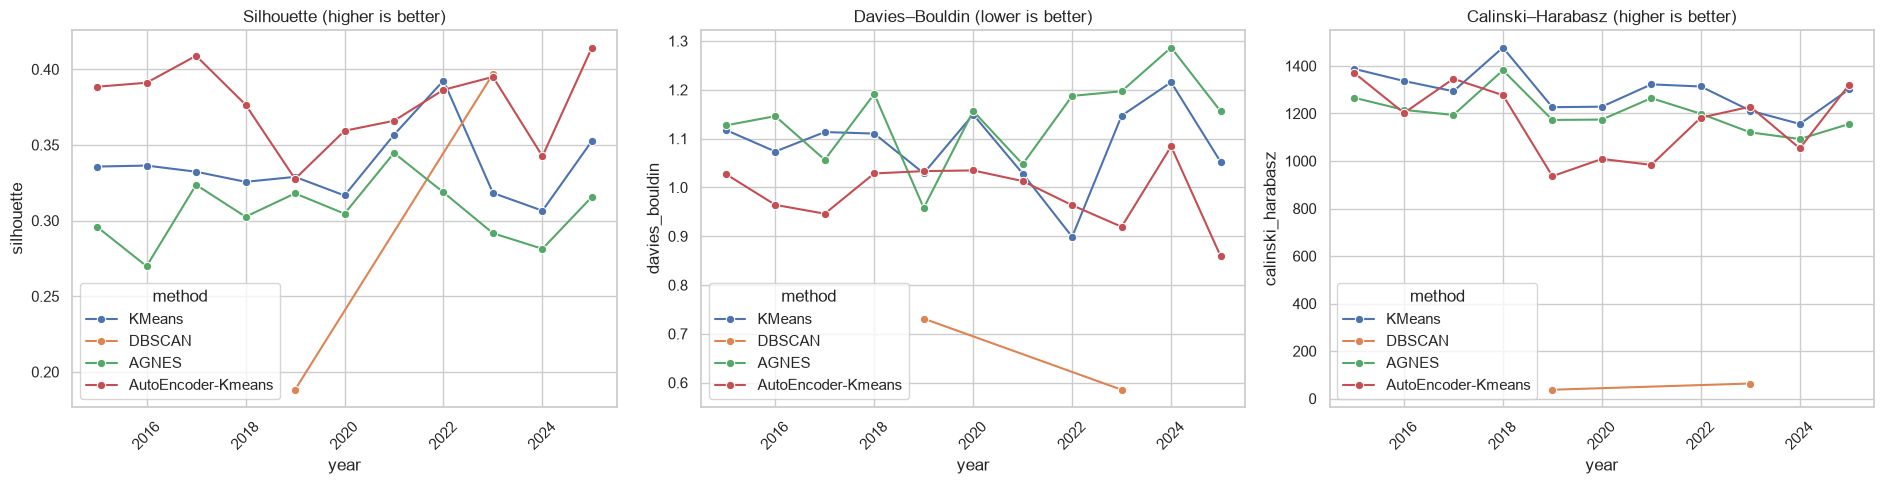

In [38]:
if not clustering_results.empty:
    fig, axes = plt.subplots(1, 3, figsize=(19, 5))
    for ax, metric, title in zip(
        axes,
        ["silhouette", "davies_bouldin", "calinski_harabasz"],
        ["Silhouette (higher is better)", "Davies–Bouldin (lower is better)", "Calinski–Harabasz (higher is better)"]
    ):
        sns.lineplot(data=clustering_results, x="year", y=metric, hue="method", marker="o", ax=ax)
        ax.set_title(title)
        ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()

## 3.4 Visualisation géographique des clusters annuels

Les étiquettes de clusters sont propres à chaque année et à chaque algorithme : le cluster `0` d'une année ne représente pas automatiquement le même régime climatique que le cluster `0` de l'année suivante. Les cartes servent donc à observer les structures spatiales, pas à supposer une correspondance directe des numéros.

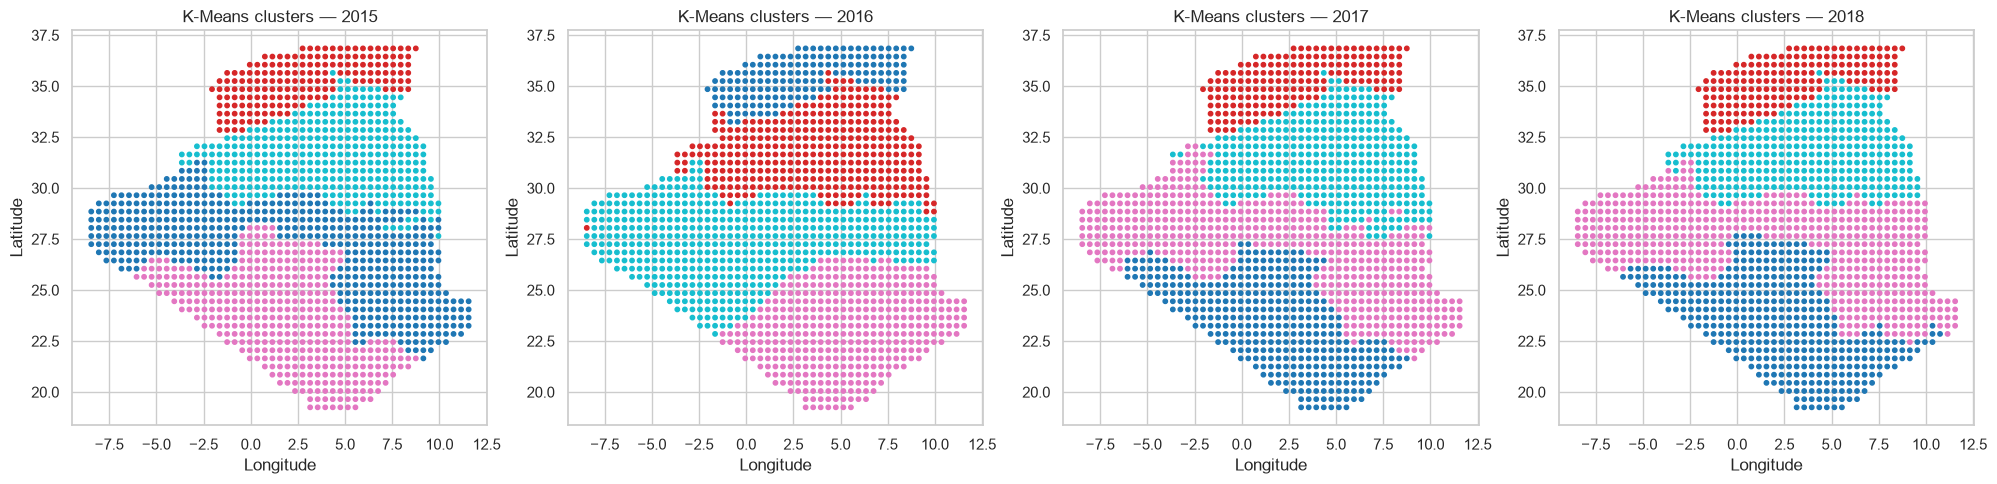

In [39]:
# Afficher les cartes K-Means pour les premières années disponibles.
# Les coordonnées sont récupérées depuis l'index multi-niveaux (latitude, longitude).
years_to_plot = sorted(annual_clustering_results)[:4]
if years_to_plot:
    fig, axes = plt.subplots(1, len(years_to_plot), figsize=(5 * len(years_to_plot), 5))
    axes = np.atleast_1d(axes)
    for ax, year in zip(axes, years_to_plot):
        res = annual_clustering_results[year]
        locs = res["profile"].index.to_frame(index=False)
        labels = res["labels"]["KMeans"]
        sc = ax.scatter(locs[lon_name], locs[lat_name], c=labels, s=10, cmap="tab10")
        ax.set_title(f"K-Means clusters — {year}")
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")
    plt.tight_layout()
    plt.show()

## 3.5 Analyse de l'évolution des clusters sur la décennie

On compare ici la proportion de cellules affectées à chaque cluster K-Means pour chaque année. Les identifiants K-Means sont recalculés indépendamment chaque année ; cette première comparaison décrit les proportions, mais une interprétation climatique longitudinale exige un alignement des clusters (par exemple en comparant les centroïdes dans l'espace des variables communes).

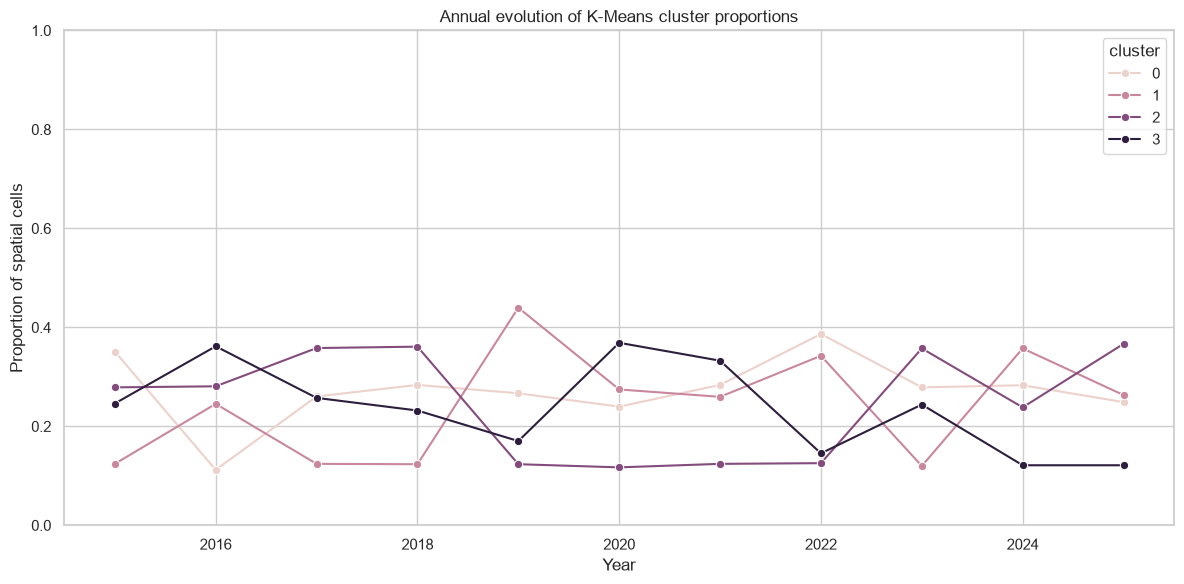

In [40]:
proportion_rows = []
for year, res in annual_clustering_results.items():
    labels = np.asarray(res["labels"]["KMeans"])
    counts = pd.Series(labels).value_counts(normalize=True).sort_index()
    for cluster_id, proportion in counts.items():
        proportion_rows.append({"year": year, "cluster": int(cluster_id), "proportion": float(proportion)})
cluster_proportions = pd.DataFrame(proportion_rows)
if not cluster_proportions.empty:
    plt.figure(figsize=(12, 6))
    sns.lineplot(data=cluster_proportions, x="year", y="proportion", hue="cluster", marker="o")
    plt.title("Annual evolution of K-Means cluster proportions")
    plt.ylabel("Proportion of spatial cells")
    plt.xlabel("Year")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()
    cluster_proportions.to_csv(RESULTS_DIR / "cluster_proportions_by_year.csv", index=False)

## 3.6 Export final des résultats

Les tableaux et figures peuvent être ajoutés au rapport. Les fichiers sont enregistrés dans le dossier `results`.

In [41]:
# Export des prédictions supervisées et des métriques de clustering.
prediction_export = test_data[[time_name, lat_name, lon_name, "target_temp", "target_class"]].copy()
for name, pred in predictions.items():
    prediction_export[f"pred_{name.replace(' ', '_')}"] = pred
prediction_export.to_csv(RESULTS_DIR / "supervised_predictions.csv", index=False)

print("Exports terminés dans :", RESULTS_DIR.resolve())
print("Fichiers :")
for path in sorted(RESULTS_DIR.glob("*")):
    print("-", path.name)

Exports terminés dans : C:\Users\DELL\Desktop\M2\data mining\results
Fichiers :
- 01_dataset_overview.csv
- 02_descriptive_statistics.csv
- 03_missing_values.csv
- 04_outliers_iqr.csv
- 05_supervised_model_comparison.csv
- 06_random_forest_feature_importance.csv
- 07_test_predictions.csv
- annual_clustering_metrics.csv
- cluster_proportions_by_year.csv
- missing_values_report.csv
- supervised_model_comparison.csv
- supervised_predictions.csv
